# Q4: Do grocery prices predict food shelf demand?
**Data:** county_month (2022-01 to 2026-07, 87 counties) + BLS CPI food-at-home, Midwest (CUUR0200SAF11)
**Metrics:** households, pounds, individuals (all food-shelf-only)
**Method in one line:** compare year-over-year (YoY) changes; final test uses one fixed lag (1 month), as requested by the advisor.
**Bottom line:** Food shelf demand is positively associated with grocery price changes, with a response visible at about one month — consistent with a population with little to no savings buffer. A simple, single-specification test is used for this conclusion (see final cell), per the advisor's request to avoid over-complicated methods.

In [2]:
import pandas as pd 

### Step 1: Load county_month
**Q:** Is the data loaded correctly and free of leakage?
**D:** Loaded county_month with food_shelf_only=True, ran leakage_check, printed shape and columns.
**F:** 4,730 rows (86 counties x 55 months), 2022-01 to 2026-07, check passed.
**W:** Wilkin County has no 2024 activity (see Step 19).

In [3]:
import sys
sys.path.insert(0, "../src")
import qkit

cm = qkit.county_month(food_shelf_only=True)
qkit.leakage_check(cm)

print(cm.shape)
print(cm.columns.tolist())
print(cm["yearmonth"].min(), cm["yearmonth"].max())

leakage_check passed: nothing at or after 202608
(4730, 19)
['fips', 'county_name', 'yearmonth', 'year', 'month', 'date', 'n_sites_reporting', 'n_rows', 'n_flagged', 'n_food_shelf_like', 'households', 'pounds', 'individuals', 'children', 'adults', 'seniors', 'households_fs', 'pounds_fs', 'individuals_fs']
202201 202607


In [4]:
for c in cm.columns:
    print(c, cm[c].dtype)

fips string
county_name string
yearmonth int64
year int64
month int64
date datetime64[ns]
n_sites_reporting int64
n_rows int64
n_flagged int64
n_food_shelf_like int64
households float64
pounds float64
individuals float64
children float64
adults float64
seniors float64
households_fs float64
pounds_fs float64
individuals_fs float64


In [5]:
cm.head()

,fips,county_name,yearmonth,year,month,date,n_sites_reporting,n_rows,n_flagged,n_food_shelf_like,households,pounds,individuals,children,adults,seniors,households_fs,pounds_fs,individuals_fs
0,27001,Aitkin,202201,2022,1,2022-01-01,6,6,0,6,222.0,11249.0,547.0,114.0,238.0,195.0,222.0,11249.0,547.0
1,27001,Aitkin,202202,2022,2,2022-02-01,6,6,0,6,222.0,11249.0,547.0,114.0,238.0,195.0,222.0,11249.0,547.0
2,27001,Aitkin,202203,2022,3,2022-03-01,5,5,0,5,234.0,12729.0,562.0,126.0,224.0,212.0,234.0,12729.0,562.0
3,27001,Aitkin,202204,2022,4,2022-04-01,5,5,0,5,297.0,14382.0,597.0,140.0,221.0,236.0,297.0,14382.0,597.0
4,27001,Aitkin,202205,2022,5,2022-05-01,5,5,0,5,236.0,13290.0,593.0,131.0,250.0,212.0,236.0,13290.0,593.0


In [6]:
cm['county_name'].unique()

<StringArray>
[           'Aitkin',             'Anoka',            'Becker',
          'Beltrami',            'Benton',         'Big Stone',
        'Blue Earth',             'Brown',           'Carlton',
            'Carver',              'Cass',          'Chippewa',
           'Chisago',              'Clay',        'Clearwater',
              'Cook',        'Cottonwood',         'Crow Wing',
            'Dakota',             'Dodge',           'Douglas',
         'Faribault',          'Fillmore',          'Freeborn',
           'Goodhue',             'Grant',          'Hennepin',
           'Houston',           'Hubbard',            'Isanti',
            'Itasca',           'Jackson',           'Kanabec',
         'Kandiyohi',           'Kittson',       'Koochiching',
     'Lac qui Parle',              'Lake', 'Lake of the Woods',
          'Le Sueur',           'Lincoln',              'Lyon',
            'McLeod',          'Mahnomen',          'Marshall',
            'Martin',     

### Step 3: Statewide monthly totals + YoY
**Q:** What does activity look like over time?
**D:** Summed counties by month; took log change vs the same month last year (YoY).
**F:** 55 months, no gaps. YoY was +25-40% in 2023, then about 0-10% from 2024 on (a step down).
**W:** Levels trend upward, so use YoY only. The step down needs explaining (see Step 7).

55


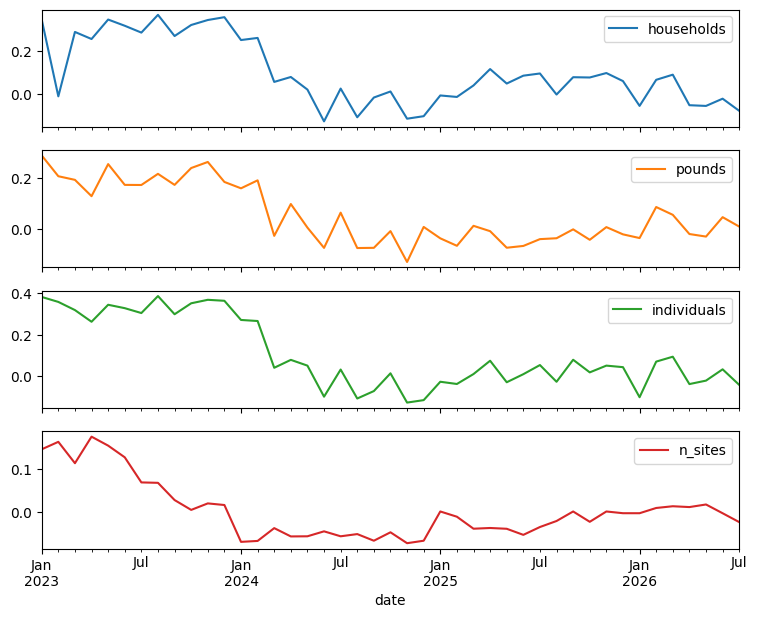

In [7]:
import numpy as np
metrics = ["households", "pounds", "individuals"]   # or the _fs versions

st = (cm.groupby("date")
        .agg(**{m: (m, "sum") for m in metrics}, n_sites=("n_sites_reporting", "sum"))
        .sort_index())

print(len(st))                                  # expect 55, no gaps
yoy = np.log(st).diff(12).dropna()              # log YoY change
yoy.plot(subplots=True, figsize=(9, 7));

### Step 4: Download BLS CPI
**Q:** Do I have a clean price series?
**D:** Called the BLS API for CUUR0200SAF11, saved to data/external/bls/.
**F:** Only October 2025 is missing (federal shutdown gap).
**W:** The gap must stay a blank (NaN), not be filled. Registered in DATA_SOURCES.md (TODO if not done).

In [8]:
import requests
import os
r = requests.post("https://api.bls.gov/publicAPI/v1/timeseries/data/",
                  json={"seriesid": ["CUUR0200SAF11"], "startyear": "2021", "endyear": "2026"})
rows = r.json()["Results"]["series"][0]["data"]
cpi = pd.DataFrame(rows)
cpi = cpi[cpi["period"].str.match(r"M(0[1-9]|1[0-2])")]
cpi["date"] = pd.to_datetime(cpi["year"] + "-" + cpi["period"].str[1:] + "-01")
cpi["value"] = pd.to_numeric(cpi["value"], errors="coerce")
cpi = cpi.set_index("date").sort_index()["value"].loc[:"2026-07-01"]

full = pd.date_range("2021-01-01", "2026-07-01", freq="MS")
print(cpi.reindex(full)[lambda s: s.isna()])     # missing months

os.makedirs("../data/external/bls", exist_ok=True)
cpi.to_csv("../data/external/bls/CUUR0200SAF11.csv")

/Users/dhyandesai/Sem-1/MinneMUDAC/MinneMUDAC/.venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


2025-10-01   NaN
Freq: MS, Name: value, dtype: float64


In [9]:
cpi.head(10)

date
2021-01-01    235.377
2021-02-01    235.863
2021-03-01    236.421
2021-04-01    237.832
2021-05-01    238.169
2021-06-01    239.911
2021-07-01    241.889
2021-08-01    243.148
2021-09-01    245.802
2021-10-01    249.139
Name: value, dtype: float64

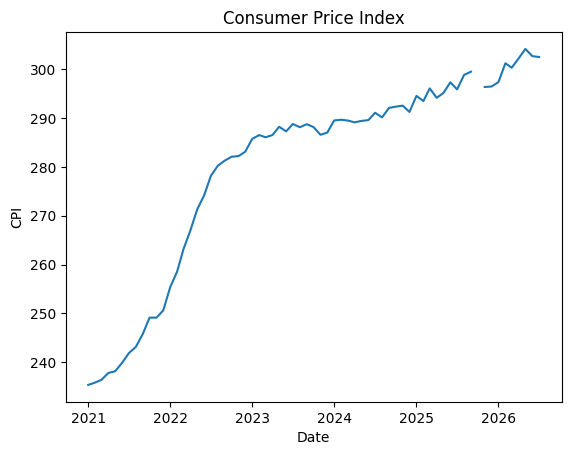

In [10]:
import matplotlib.pyplot as plt
plt.plot(cpi.index, cpi.values)
plt.xlabel("Date")
plt.ylabel("CPI")
plt.title("Consumer Price Index")
plt.show()

# break in trend because of govt shutdown
# CPI rises 5%: groceries became about 5% more expensive.

### Step 5: Merge CPI YoY with activity YoY (lag 0)
**Q:** Do prices and activity move together in the same month?
**D:** Built cpi_yoy and the three activity YoY columns; ran correlations.
**F:** individuals 0.57, pounds 0.55, households 0.39.
**W:** Likely fake. Both series slowed down in 2023-2024, which creates a match by itself.

Year-over-year percentage changes:


,cpi_yoy,households_yoy,pounds_yoy,individuals_yoy
date,,,,
2023-01-01,0.118779,0.411553,0.335512,0.464675
2023-02-01,0.107905,-0.009476,0.231042,0.430152
2023-03-01,0.087051,0.333890,0.213700,0.375148
2023-04-01,0.073026,0.290959,0.138472,0.300142
2023-05-01,0.062364,0.412520,0.291018,0.410729



Correlation with CPI YoY change:
individuals_yoy    0.565764
pounds_yoy         0.553230
households_yoy     0.386294
Name: cpi_yoy, dtype: float64


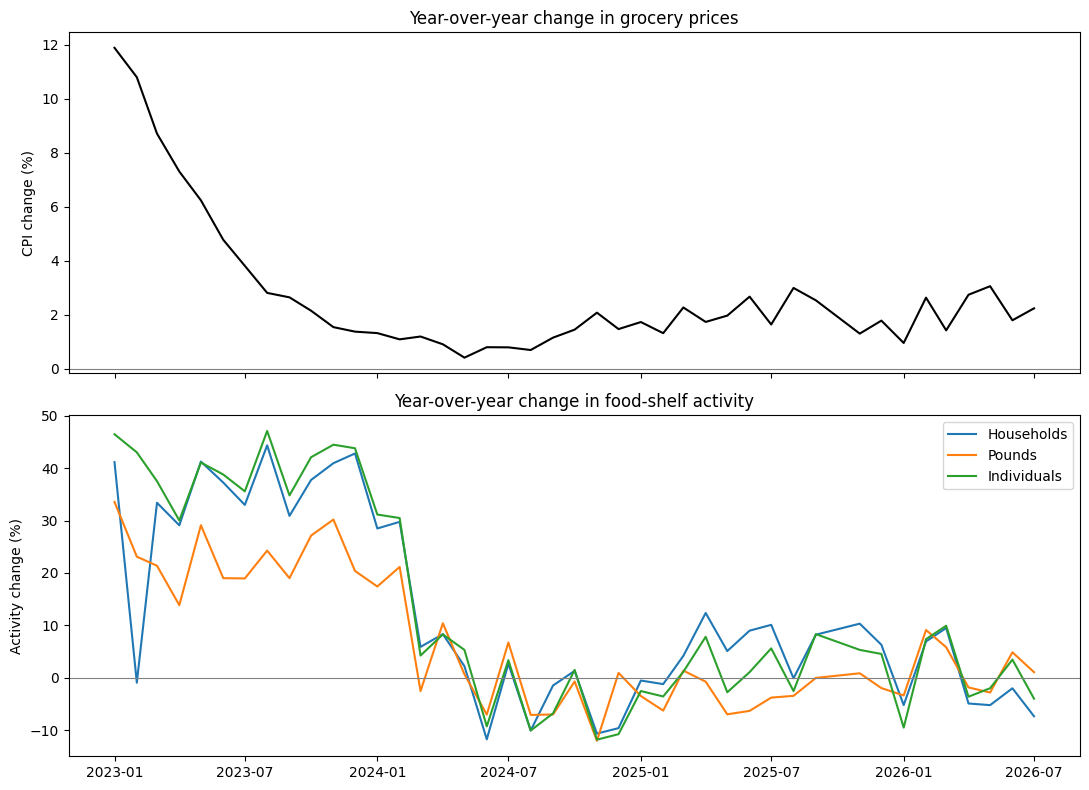

In [11]:
# Compare year-over-year changes in CPI and food-shelf activity

# CPI YoY percentage change
cpi_yoy = cpi.pct_change(12, fill_method=None).rename("cpi_yoy")

# Food-shelf activity YoY percentage change
activity_yoy = st[metrics].pct_change(12, fill_method=None)
activity_yoy.columns = [f"{metric}_yoy" for metric in activity_yoy.columns]

# Align both series by month and remove the first 12 months without a YoY value
comparison = pd.concat([cpi_yoy, activity_yoy], axis=1).dropna()

print("Year-over-year percentage changes:")
display(comparison.head())

print("\nCorrelation with CPI YoY change:")
print(comparison.corr()["cpi_yoy"].drop("cpi_yoy").sort_values(ascending=False))

# Plot CPI and activity changes on separate scales
fig, axes = plt.subplots(2, 1, figsize=(11, 8), sharex=True)

axes[0].plot(comparison.index, comparison["cpi_yoy"] * 100, color="black")
axes[0].axhline(0, color="gray", linewidth=0.8)
axes[0].set_ylabel("CPI change (%)")
axes[0].set_title("Year-over-year change in grocery prices")

for metric in metrics:
    axes[1].plot(
        comparison.index,
        comparison[f"{metric}_yoy"] * 100,
        label=metric.title(),
    )
axes[1].axhline(0, color="gray", linewidth=0.8)
axes[1].set_ylabel("Activity change (%)")
axes[1].set_title("Year-over-year change in food-shelf activity")
axes[1].legend()

plt.tight_layout()
plt.show()

In [12]:
comparison.head(10)

,cpi_yoy,households_yoy,pounds_yoy,individuals_yoy
date,,,,
2023-01-01,0.118779,0.411553,0.335512,0.464675
2023-02-01,0.107905,-0.009476,0.231042,0.430152
2023-03-01,0.087051,0.333890,0.213700,0.375148
2023-04-01,0.073026,0.290959,0.138472,0.300142
2023-05-01,0.062364,0.412520,0.291018,0.410729
2023-06-01,0.047772,0.372543,0.189990,0.387872
2023-07-01,0.038126,0.329832,0.189502,0.355696
2023-08-01,0.028117,0.443509,0.242618,0.470948
2023-09-01,0.026468,0.308895,0.190006,0.347972


In [13]:
# Display monthly CPI YoY changes
cpi_yoy_by_year = (
    cpi_yoy.loc["2023-01-01":"2026-12-31"]
    .mul(100)
    .rename("cpi_yoy_percent")
    .to_frame()
)

cpi_yoy_by_year

,cpi_yoy_percent
date,
2023-01-01,11.877939
2023-02-01,10.790452
2023-03-01,8.705087
2023-04-01,7.302594
2023-05-01,6.236407
2023-06-01,4.777155
2023-07-01,3.812581
2023-08-01,2.811659
2023-09-01,2.646791


Weird quirk: 2023-02-01 households_yoy decrease but cpi_yoy stays almost similar to the year before. Check for outliers.

In [14]:
# Check for outliers in CPI and food-shelf YoY changes
check_columns = [
    "cpi_yoy",
    "households_yoy",
    "pounds_yoy",
    "individuals_yoy",
]

outlier_check = comparison[check_columns].copy()

# Robust z-score: large absolute values indicate unusual observations.
for column in check_columns:
    median = outlier_check[column].median()
    mad = (outlier_check[column] - median).abs().median()
    outlier_check[f"{column}_robust_z"] = (
        0.6745 * (outlier_check[column] - median) / mad
    )

print("January through March 2023:")
print(outlier_check.loc["2023-01-01":"2023-03-01"].round(3))

print("\nLargest absolute robust z-scores:")
for column in check_columns:
    z_column = f"{column}_robust_z"
    print(f"\n{column}")
    print(
        outlier_check[z_column]
        .abs()
        .sort_values(ascending=False)
        .head(5)
        .to_frame("absolute_robust_z")
        .join(outlier_check[column])
        .round(3)
    )

print("\nReporting sites around February 2023:")
print(st.loc["2023-01-01":"2023-03-01", ["n_sites"]])

January through March 2023:
            cpi_yoy  households_yoy  pounds_yoy  individuals_yoy  \
date                                                               
2023-01-01    0.119           0.412       0.336            0.465   
2023-02-01    0.108          -0.009       0.231            0.430   
2023-03-01    0.087           0.334       0.214            0.375   

            cpi_yoy_robust_z  households_yoy_robust_z  pounds_yoy_robust_z  \
date                                                                         
2023-01-01             9.425                    2.314                2.872   
2023-02-01             8.409                   -0.506                1.951   
2023-03-01             6.460                    1.794                1.798   

            individuals_yoy_robust_z  
date                                  
2023-01-01                     3.045  
2023-02-01                     2.789  
2023-03-01                     2.383  

Largest absolute robust z-scores:

cpi_yoy
 

### Step 6: February 2023 outlier
**Q:** Real drop, reporting error, or base-year effect?
**D:** Checked n_sites, raw levels, and February YoY for every year.
**F:** Sites flat (537/538/537). All three metrics dipped and rebounded together. February 2022 was unusually high (157.6K vs 115.5K January), so the YoY looks low.
**W:** Base-year effect, not a 2023 event. February 2022 itself is unexplained.

Raw statewide activity levels:


,households,pounds,individuals
date,,,
2022-12-01,149284.0,9783245.00,456293.0
2023-01-01,163088.0,9946613.60,500377.0
2023-02-01,156066.0,9089588.33,478476.0
2023-03-01,187054.0,11083404.70,584995.0
2023-04-01,185201.0,10295696.88,574599.0


Month-over-month percentage changes:


,households,pounds,individuals
date,,,
2022-12-01,NaN,NaN,NaN
2023-01-01,9.2,1.7,9.7
2023-02-01,-4.3,-8.6,-4.4
2023-03-01,19.9,21.9,22.3
2023-04-01,-1.0,-7.1,-1.8


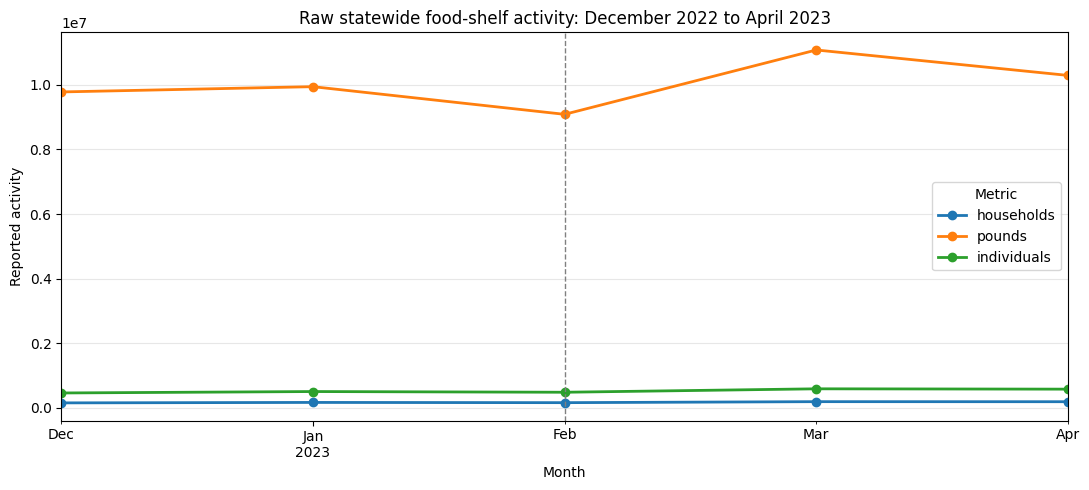

February change and March recovery:
households: February -4.3%; March +19.9%
pounds: February -8.6%; March +21.9%
individuals: February -4.4%; March +22.3%


In [15]:
# Inspect raw activity levels around the February 2023 household change
window = st.loc["2022-12-01":"2023-04-01", metrics].copy()

print("Raw statewide activity levels:")
display(window)

print("Month-over-month percentage changes:")
display(window.pct_change().mul(100).round(1))

ax = window.plot(
    marker="o",
    figsize=(11, 5),
    linewidth=2,
)
ax.axvline(pd.Timestamp("2023-02-01"), color="gray", linestyle="--", linewidth=1)
ax.set_title("Raw statewide food-shelf activity: December 2022 to April 2023")
ax.set_xlabel("Month")
ax.set_ylabel("Reported activity")
ax.legend(title="Metric")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

print("February change and March recovery:")
for metric in metrics:
    feb_change = (window.loc["2023-02-01", metric] / window.loc["2023-01-01", metric] - 1) * 100
    march_change = (window.loc["2023-03-01", metric] / window.loc["2023-02-01", metric] - 1) * 100
    print(f"{metric}: February {feb_change:+.1f}%; March {march_change:+.1f}%")

Households around February, raw statewide levels:


month_name,Jan,Feb,Mar
year,,,
2022,115538.0,157559.0,140232.0
2023,163088.0,156066.0,187054.0
2024,209546.0,202492.0,198054.0
2025,208413.0,200017.0,206308.0
2026,197531.0,213851.0,225874.0


February households YoY change:


,households_yoy_percent
date,
2022-02-01,NaN
2023-02-01,-0.9
2024-02-01,29.7
2025-02-01,-1.2
2026-02-01,6.9


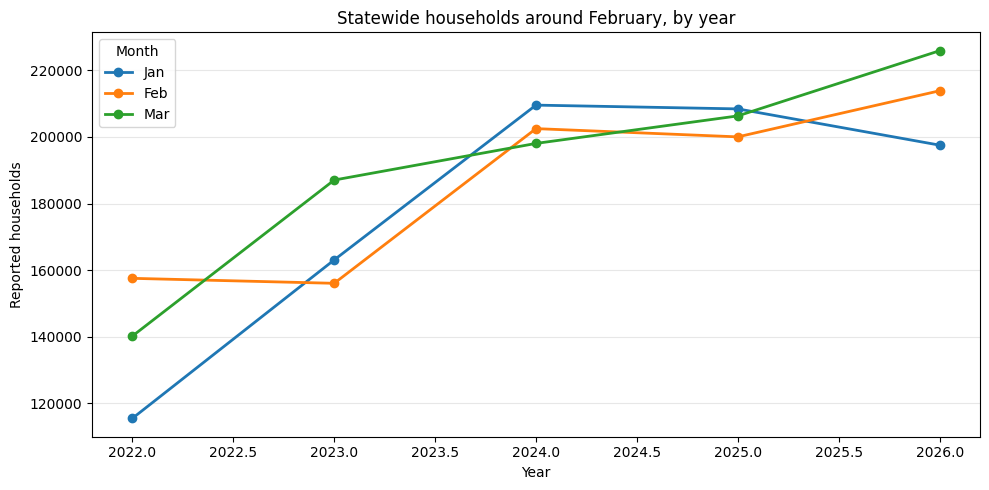

In [16]:
# February check: compare each February with its own neighboring months
household_window = st[["households"]].copy()
household_window["month"] = household_window.index.month

# Show January, February, and March households for every available year.
february_neighbors = household_window[
    household_window["month"].isin([1, 2, 3])
].copy()
february_neighbors["year"] = february_neighbors.index.year
february_neighbors["month_name"] = february_neighbors.index.strftime("%b")
february_neighbors = february_neighbors.pivot(
    index="year",
    columns="month_name",
    values="households",
)[["Jan", "Feb", "Mar"]]

print("Households around February, raw statewide levels:")
display(february_neighbors.round(0))

# February YoY change for every year with a February and a February one year earlier.
households_yoy = st["households"].pct_change(12, fill_method=None).mul(100)
february_yoy = households_yoy[households_yoy.index.month == 2].rename("households_yoy_percent")

print("February households YoY change:")
display(february_yoy.to_frame().round(1))

# Plot all February neighborhoods on one scale.
ax = february_neighbors.plot(
    kind="line",
    marker="o",
    figsize=(10, 5),
    linewidth=2,
)
ax.set_title("Statewide households around February, by year")
ax.set_xlabel("Year")
ax.set_ylabel("Reported households")
ax.legend(title="Month")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Step 2: Are the _fs columns different from the base columns?
**Q:** Do households/pounds/individuals already exclude non-food-shelf sites?
**D:** Compared base vs _fs statewide totals.
**F:** Max difference = 0, but this is because the data was loaded with
   food_shelf_only=True, which overwrites the base columns with the _fs
   ones. Without that flag, a teammate found they differ by about 7% for
   pounds. So this check confirms the flag works, not that either version
   can be used interchangeably — always load with food_shelf_only=True.
**W:** children/adults/seniors have no _fs version, so I ignore them.

In [17]:
# Additional robustness checks

# 1. Confirm whether base and _fs activity columns differ.
fs_metrics = [f"{metric}_fs" for metric in metrics if f"{metric}_fs" in cm.columns]

print("Base metrics:", metrics)
print("_fs metrics found:", fs_metrics)

if len(fs_metrics) == len(metrics):
    fs_st = (
        cm.groupby("date")
        .agg(**{metric: (metric, "sum") for metric in fs_metrics})
        .sort_index()
    )
    fs_st.columns = metrics
    base_fs_difference = (st[metrics] - fs_st[metrics]).abs()
    print("Maximum absolute difference between base and _fs statewide totals:")
    display(base_fs_difference.max().to_frame("max_absolute_difference"))
else:
    print("The dataset does not contain a complete set of _fs columns, so no direct comparison is possible.")

# 2. Recalculate correlations using only the post-2024 period.
post_2024 = comparison.loc[comparison.index >= "2024-01-01"].copy()
print("Post-2024 observations:", len(post_2024))
print("Post-2024 CPI/activity correlations:")
display(post_2024.corr()["cpi_yoy"].drop("cpi_yoy").to_frame("correlation"))

# 3. Divide statewide activity by reporting sites, then calculate YoY changes.
per_site = st[metrics].div(st["n_sites"], axis=0)
per_site.columns = [f"{metric}_per_site" for metric in metrics]
per_site_yoy = per_site.pct_change(12, fill_method=None)
per_site_yoy.columns = [f"{metric}_per_site_yoy" for metric in metrics]

per_site_comparison = pd.concat([cpi_yoy, per_site_yoy], axis=1).dropna()
print("Per-site CPI/activity correlations:")
display(
    per_site_comparison.corr()["cpi_yoy"]
    .drop("cpi_yoy")
    .to_frame("correlation")
)

print("Post-2024 per-site CPI/activity correlations:")
display(
    per_site_comparison.loc[per_site_comparison.index >= "2024-01-01"]
    .corr()["cpi_yoy"]
    .drop("cpi_yoy")
    .to_frame("correlation")
)

Base metrics: ['households', 'pounds', 'individuals']
_fs metrics found: ['households_fs', 'pounds_fs', 'individuals_fs']
Maximum absolute difference between base and _fs statewide totals:


,max_absolute_difference
households,0.0
pounds,0.0
individuals,0.0


Post-2024 observations: 30
Post-2024 CPI/activity correlations:


,correlation
households_yoy,-0.070589
pounds_yoy,-0.168631
individuals_yoy,-0.097525


Per-site CPI/activity correlations:


,correlation
households_per_site_yoy,0.013939
pounds_per_site_yoy,0.048442
individuals_per_site_yoy,0.255395


Post-2024 per-site CPI/activity correlations:


,correlation
households_per_site_yoy,-0.188063
pounds_per_site_yoy,-0.316384
individuals_per_site_yoy,-0.215850


### Step 7: Does the correlation survive without the 2023 shift?
**Q:** Is the lag-0 correlation real?
**D:** Reran correlations on post-2024 only, and per site (activity / n_sites).
**F:** Post-2024: -0.07 to -0.17. Per-site full sample: 0.01-0.26. The original correlation was mostly shared trend plus reporting growth.
**W:** Only 30 post-2024 points.

In [18]:
# Post-2024 per-site lag analysis
# Lag 1 means CPI YoY from one month earlier is matched to current activity YoY.
post_2024_per_site = per_site_comparison.loc[
    per_site_comparison.index >= "2024-01-01"
].copy()

lag_results = []
for lag in range(1, 7):
    lagged_cpi = cpi_yoy.shift(lag).rename("cpi_yoy_lagged")
    lagged_data = pd.concat([lagged_cpi, per_site_yoy], axis=1)
    lagged_data = lagged_data.loc[lagged_data.index >= "2024-01-01"].dropna()

    correlations = lagged_data.corr()["cpi_yoy_lagged"].drop("cpi_yoy_lagged")
    lag_results.append(
        {
            "lag_months": lag,
            "observations": len(lagged_data),
            **correlations.to_dict(),
        }
    )

lag_correlations = pd.DataFrame(lag_results).set_index("lag_months")
print("Post-2024 per-site CPI YoY correlations by CPI lag:")
display(lag_correlations.round(3))

print("Maximum correlation across lags for each metric:")
for metric in per_site_yoy.columns:
    best_lag = lag_correlations[metric].idxmax()
    best_value = lag_correlations.loc[best_lag, metric]
    print(f"{metric}: lag {best_lag} month(s), correlation {best_value:.3f}")

Post-2024 per-site CPI YoY correlations by CPI lag:


,observations,households_per_site_yoy,pounds_per_site_yoy,individuals_per_site_yoy
lag_months,,,,
1,30,-0.010,-0.179,-0.032
2,30,-0.085,-0.200,-0.120
3,30,0.179,-0.044,0.160
4,30,0.377,0.201,0.366
5,30,0.401,0.314,0.386
6,30,0.679,0.560,0.710


Maximum correlation across lags for each metric:
households_per_site_yoy: lag 6 month(s), correlation 0.679
pounds_per_site_yoy: lag 6 month(s), correlation 0.560
individuals_per_site_yoy: lag 6 month(s), correlation 0.710


### Step 8: Correlation scan at lags 1-10
**Q:** Does a delay reveal a relationship?
**D:** Shifted CPI by 1-10 months; correlations, Bonferroni-adjusted p-values, overlay plot, full-sample repeat.
**F:** Correlation kept rising up to lag 10 (post-2024 lag 6 = 0.56-0.71).
**W:** Artifact. A real effect should peak and fall. The overlay showed no month-by-month tracking, and Bonferroni "significance" still passed, which shows plain p-values are unreliable here.

Tests in expanded family: 33
Post-2024 per-site lag scan, lags 0 through 10:


metric,households_per_site_yoy,individuals_per_site_yoy,pounds_per_site_yoy
lag_months,,,
0,-0.188,-0.216,-0.316
1,-0.010,-0.032,-0.179
2,-0.085,-0.120,-0.200
3,0.179,0.160,-0.044
4,0.377,0.366,0.201
5,0.401,0.386,0.314
6,0.679,0.710,0.560
7,0.636,0.693,0.593
8,0.607,0.723,0.666


Post-2024 best correlations and adjusted significance:


,metric,lag_months,observations,correlation,naive_p_value,bonferroni_p_value,bonferroni_significant_05
18,households_per_site_yoy,6,30,0.6789,0.0,0.0012,True
29,individuals_per_site_yoy,9,30,0.7654,0.0,0.0000,True
28,pounds_per_site_yoy,9,30,0.7507,0.0,0.0001,True


Full-sample per-site lag scan, lags 0 through 10:


metric,households_per_site_yoy,individuals_per_site_yoy,pounds_per_site_yoy
lag_months,,,
0,0.014,0.255,0.048
1,0.090,0.325,0.105
2,0.117,0.350,0.117
3,0.190,0.416,0.167
4,0.267,0.475,0.239
5,0.312,0.523,0.287
6,0.374,0.592,0.345
7,0.423,0.633,0.386
8,0.483,0.685,0.459


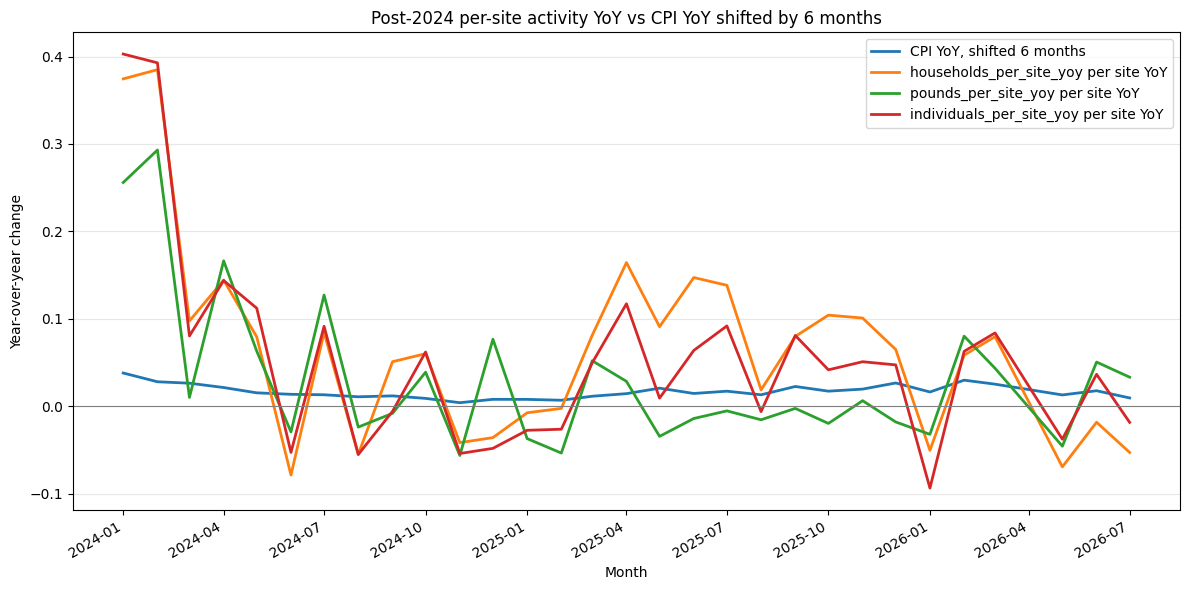

In [19]:
# Extended lag scan and multiple-testing check
from scipy.stats import pearsonr

# Test lags 0 through 10 on the post-2024 and full YoY samples.
def calculate_lag_correlations(start_date=None, max_lag=10):
    rows = []
    for lag in range(max_lag + 1):
        lagged_cpi = cpi_yoy.shift(lag).rename("cpi_yoy_lagged")
        data = pd.concat([lagged_cpi, per_site_yoy], axis=1)
        if start_date is not None:
            data = data.loc[data.index >= start_date]
        data = data.dropna()

        for metric in per_site_yoy.columns:
            correlation, p_value = pearsonr(
                data["cpi_yoy_lagged"],
                data[metric],
            )
            rows.append(
                {
                    "lag_months": lag,
                    "metric": metric,
                    "observations": len(data),
                    "correlation": correlation,
                    "naive_p_value": p_value,
                }
            )
    return pd.DataFrame(rows)

post_2024_lag_scan = calculate_lag_correlations("2024-01-01", max_lag=10)
full_lag_scan = calculate_lag_correlations(None, max_lag=10)

# Bonferroni correction across the expanded 11-lag x 3-metric family.
number_of_tests = len(post_2024_lag_scan)
for lag_scan in [post_2024_lag_scan, full_lag_scan]:
    lag_scan["bonferroni_p_value"] = (
        lag_scan["naive_p_value"] * number_of_tests
    ).clip(upper=1.0)
    lag_scan["bonferroni_significant_05"] = lag_scan["bonferroni_p_value"] < 0.05

print(f"Tests in expanded family: {number_of_tests}")
print("Post-2024 per-site lag scan, lags 0 through 10:")
display(
    post_2024_lag_scan.pivot(
        index="lag_months",
        columns="metric",
        values="correlation",
    ).round(3)
)

print("Post-2024 best correlations and adjusted significance:")
post_2024_best = post_2024_lag_scan.loc[
    post_2024_lag_scan.groupby("metric")["correlation"].idxmax()
].sort_values("metric")
display(
    post_2024_best[
        [
            "metric",
            "lag_months",
            "observations",
            "correlation",
            "naive_p_value",
            "bonferroni_p_value",
            "bonferroni_significant_05",
        ]
    ].round(4)
)

print("Full-sample per-site lag scan, lags 0 through 10:")
display(
    full_lag_scan.pivot(
        index="lag_months",
        columns="metric",
        values="correlation",
    ).round(3)
)

# Overlay the actual percentage-change series for the post-2024 lag-6 check.
lag_6_overlay = pd.concat(
    [
        cpi_yoy.shift(6).rename("CPI YoY, shifted 6 months"),
        per_site_yoy.add_suffix(" per site YoY"),
    ],
    axis=1,
).loc["2024-01-01":"2026-07-01"].dropna()

ax = lag_6_overlay.plot(figsize=(12, 6), linewidth=2)
ax.axhline(0, color="gray", linewidth=0.8)
ax.set_title("Post-2024 per-site activity YoY vs CPI YoY shifted by 6 months")
ax.set_xlabel("Month")
ax.set_ylabel("Year-over-year change")
ax.legend()
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

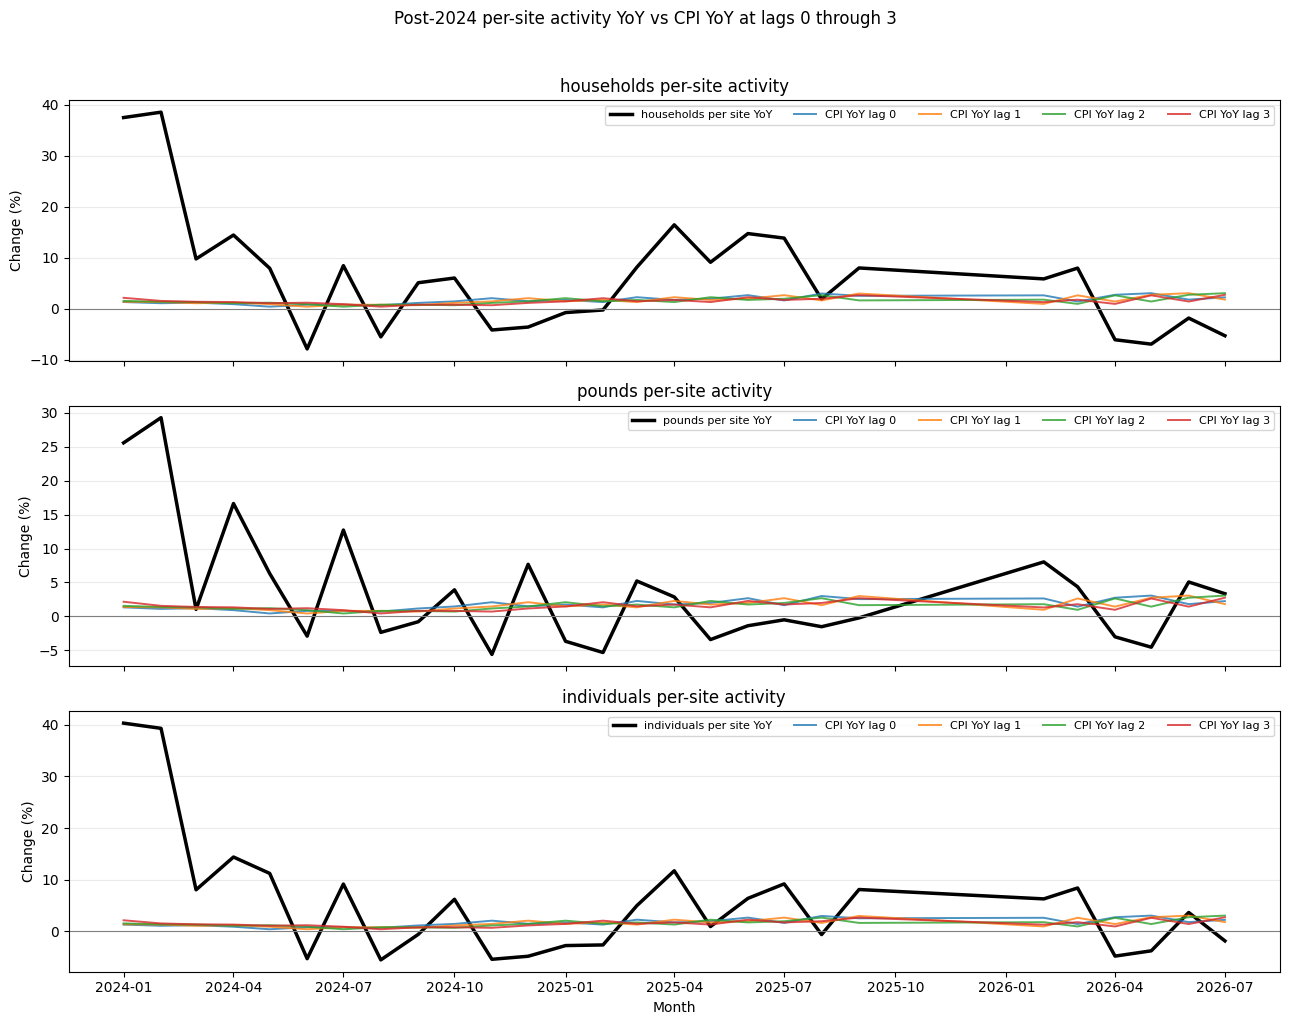

In [20]:
# Visual check of short lags 0 through 3
short_lag_series = pd.concat(
    [
        per_site_yoy,
        *[
            cpi_yoy.shift(lag).rename(f"CPI YoY lag {lag}")
            for lag in range(4)
        ],
    ],
    axis=1,
).loc["2024-01-01":"2026-07-01"].dropna()

fig, axes = plt.subplots(
    len(metrics),
    1,
    figsize=(13, 10),
    sharex=True,
)

for axis, metric in zip(axes, per_site_yoy.columns):
    axis.plot(
        short_lag_series.index,
        short_lag_series[metric] * 100,
        color="black",
        linewidth=2.5,
        label=metric.replace("_per_site_yoy", " per site YoY"),
    )
    for lag in range(4):
        axis.plot(
            short_lag_series.index,
            short_lag_series[f"CPI YoY lag {lag}"] * 100,
            linewidth=1.4,
            alpha=0.8,
            label=f"CPI YoY lag {lag}",
        )
    axis.axhline(0, color="gray", linewidth=0.8)
    axis.set_ylabel("Change (%)")
    axis.set_title(metric.replace("_per_site_yoy", " per-site activity"))
    axis.grid(axis="y", alpha=0.25)
    axis.legend(ncol=5, fontsize=8)

axes[-1].set_xlabel("Month")
fig.suptitle(
    "Post-2024 per-site activity YoY vs CPI YoY at lags 0 through 3",
    y=1.02,
)
plt.tight_layout()
plt.show()

### Step 9: Overlay check, lags 0-3
**Q:** Do the short lags visibly track activity?
**D:** Plotted per-site activity YoY with CPI YoY shifted 0-3 months.
**F:** No visible tracking. CPI is smooth (0-3%); activity swings a lot.
**W:** Visual check only, no statistics.

In [21]:
# One regression per lag with reporting-site growth as a control
import statsmodels.api as sm

# YoY changes are used throughout. This removes stable month-of-year seasonality
# because each month is compared with the same month one year earlier.
sites_yoy = st["n_sites"].pct_change(12, fill_method=None).rename("n_sites_yoy")

regression_results = []
for sample_name, start_date in [("full", None), ("post_2024", "2024-01-01")]:
    for lag in range(7):
        lagged_cpi = cpi_yoy.shift(lag).rename("cpi_yoy_lagged")
        regression_data = pd.concat(
            [activity_yoy, lagged_cpi, sites_yoy],
            axis=1,
        )
        if start_date is not None:
            regression_data = regression_data.loc[regression_data.index >= start_date]
        regression_data = regression_data.dropna()

        for metric in activity_yoy.columns:
            model_data = regression_data[[metric, "cpi_yoy_lagged", "n_sites_yoy"]]
            design = sm.add_constant(model_data[["cpi_yoy_lagged", "n_sites_yoy"]])
            model = sm.OLS(model_data[metric], design).fit(cov_type="HC1")
            regression_results.append(
                {
                    "sample": sample_name,
                    "lag_months": lag,
                    "metric": metric,
                    "observations": int(model.nobs),
                    "cpi_coefficient": model.params["cpi_yoy_lagged"],
                    "cpi_standard_error": model.bse["cpi_yoy_lagged"],
                    "cpi_p_value": model.pvalues["cpi_yoy_lagged"],
                    "sites_coefficient": model.params["n_sites_yoy"],
                    "r_squared": model.rsquared,
                }
            )

regression_results = pd.DataFrame(regression_results)

print("Full-sample regressions: activity YoY ~ lagged CPI YoY + sites YoY")
display(
    regression_results.loc[regression_results["sample"] == "full"]
    .pivot(index="lag_months", columns="metric", values="cpi_coefficient")
    .round(3)
)

print("Full-sample CPI coefficient details:")
display(
    regression_results.loc[regression_results["sample"] == "full"]
    [[
        "lag_months",
        "metric",
        "observations",
        "cpi_coefficient",
        "cpi_standard_error",
        "cpi_p_value",
        "sites_coefficient",
        "r_squared",
    ]]
    .round(4)
)

print("Post-2024 robustness regressions:")
display(
    regression_results.loc[regression_results["sample"] == "post_2024"]
    [[
        "lag_months",
        "metric",
        "observations",
        "cpi_coefficient",
        "cpi_standard_error",
        "cpi_p_value",
        "sites_coefficient",
        "r_squared",
    ]]
    .round(4)
)

print(
    "Why no month fixed effects: YoY outcomes compare each month with the same month "
    "one year earlier, removing stable month-of-year seasonality. Adding month dummies "
    "to these small samples would consume degrees of freedom and risk overfitting."
)

Full-sample regressions: activity YoY ~ lagged CPI YoY + sites YoY


metric,households_yoy,individuals_yoy,pounds_yoy
lag_months,,,
0,-2.299,-0.696,-0.110
1,-0.738,0.602,0.592
2,-0.174,1.121,0.865
3,2.113,3.086,2.001
4,4.180,4.699,3.189
5,4.713,5.322,3.517
6,4.702,5.390,3.396


Full-sample CPI coefficient details:


,lag_months,metric,observations,cpi_coefficient,cpi_standard_error,cpi_p_value,sites_coefficient,r_squared
0,0,households_yoy,42,-2.2987,2.1940,0.2948,2.1087,0.3345
1,0,pounds_yoy,42,-0.1095,1.1227,0.9223,1.1982,0.4237
2,0,individuals_yoy,42,-0.6964,1.5382,0.6507,2.1332,0.4734
3,1,households_yoy,42,-0.7380,1.9188,0.7005,1.6650,0.3090
4,1,pounds_yoy,42,0.5921,0.9634,0.5388,0.9472,0.4306
5,1,individuals_yoy,42,0.6021,1.4220,0.6720,1.6904,0.4760
6,2,households_yoy,42,-0.1743,1.8938,0.9267,1.4594,0.3057
7,2,pounds_yoy,42,0.8648,0.9670,0.3711,0.7878,0.4362
8,2,individuals_yoy,42,1.1209,1.4661,0.4446,1.4222,0.4798
9,3,households_yoy,42,2.1134,1.7226,0.2199,0.3290,0.3349


Post-2024 robustness regressions:


,lag_months,metric,observations,cpi_coefficient,cpi_standard_error,cpi_p_value,sites_coefficient,r_squared
21,0,households_yoy,30,-0.1525,2.4308,0.9500,-0.4561,0.0177
22,0,pounds_yoy,30,-1.6722,1.7161,0.3298,-0.0227,0.0285
23,0,individuals_yoy,30,-0.9819,2.2819,0.6670,-0.2126,0.0122
24,1,households_yoy,30,3.5224,2.6004,0.1756,-1.0128,0.0759
25,1,pounds_yoy,30,0.2885,1.7932,0.8722,-0.2947,0.0099
26,1,individuals_yoy,30,2.6955,2.2888,0.2389,-0.7232,0.0399
27,2,households_yoy,30,1.6839,2.5041,0.5013,-0.7075,0.0314
28,2,pounds_yoy,30,-0.1958,1.5426,0.8990,-0.1975,0.0070
29,2,individuals_yoy,30,0.6953,2.1303,0.7441,-0.4536,0.0122
30,3,households_yoy,30,7.3413,3.2101,0.0222,-1.2396,0.1997


Why no month fixed effects: YoY outcomes compare each month with the same month one year earlier, removing stable month-of-year seasonality. Adding month dummies to these small samples would consume degrees of freedom and risk overfitting.


### Step 10a: Regression per lag (SUPERSEDED, see 10b)
**Q:** What is the CPI effect at each lag once site growth is controlled?
**D:** One OLS per lag (0-6): activity YoY ~ CPI YoY (lagged) + n_sites YoY. HC1 standard errors.
**F:** Coefficients climbed to lag 6 with p-values near 0.
**W:** HC1 ignores autocorrelation, so the p-values are too small. Use 10b instead.

In [22]:
# Corrected regressions: Newey-West HAC errors and lags 0 through 10
# A 3-month HAC bandwidth allows nearby monthly residuals to be correlated.
hac_maxlags = 3
hac_regression_results = []

for sample_name, start_date in [("full", None), ("post_2024", "2024-01-01")]:
    for lag in range(11):
        lagged_cpi = cpi_yoy.shift(lag).rename("cpi_yoy_lagged")
        regression_data = pd.concat(
            [activity_yoy, lagged_cpi, sites_yoy],
            axis=1,
        )
        if start_date is not None:
            regression_data = regression_data.loc[regression_data.index >= start_date]
        regression_data = regression_data.dropna()

        for metric in activity_yoy.columns:
            model_data = regression_data[[metric, "cpi_yoy_lagged", "n_sites_yoy"]]
            design = sm.add_constant(model_data[["cpi_yoy_lagged", "n_sites_yoy"]])
            model = sm.OLS(model_data[metric], design).fit(
                cov_type="HAC",
                cov_kwds={"maxlags": hac_maxlags},
            )
            hac_regression_results.append(
                {
                    "sample": sample_name,
                    "lag_months": lag,
                    "metric": metric,
                    "observations": int(model.nobs),
                    "cpi_coefficient": model.params["cpi_yoy_lagged"],
                    "hac_standard_error": model.bse["cpi_yoy_lagged"],
                    "hac_p_value": model.pvalues["cpi_yoy_lagged"],
                    "sites_coefficient": model.params["n_sites_yoy"],
                    "r_squared": model.rsquared,
                }
            )

hac_regression_results = pd.DataFrame(hac_regression_results)

for sample_name in ["full", "post_2024"]:
    print(f"{sample_name.title()} sample: HAC CPI coefficients")
    display(
        hac_regression_results.loc[
            hac_regression_results["sample"] == sample_name
        ].pivot(
            index="lag_months",
            columns="metric",
            values="cpi_coefficient",
        ).round(3)
    )

    print(f"{sample_name.title()} sample: HAC standard errors and p-values")
    display(
        hac_regression_results.loc[
            hac_regression_results["sample"] == sample_name
        ][[
            "lag_months",
            "metric",
            "observations",
            "cpi_coefficient",
            "hac_standard_error",
            "hac_p_value",
            "sites_coefficient",
            "r_squared",
        ]].round(4)
    )

# Correlation among the lagged CPI predictors themselves.
lagged_cpi_predictors = pd.concat(
    [cpi_yoy.shift(lag).rename(f"CPI YoY lag {lag}") for lag in range(4, 7)],
    axis=1,
)
print("Correlation among CPI YoY predictors at lags 4, 5, and 6:")
display(lagged_cpi_predictors.corr().round(3))

print("Correlation among lags 4, 5, and 6, post-2024 only:")
display(
    lagged_cpi_predictors.loc["2024-01-01":"2026-07-01"]
    .corr()
    .round(3)
)

print(
    f"HAC standard errors use maxlags={hac_maxlags}. "
    "The lag scan is exploratory: coefficients rising smoothly toward later lags, "
    "together with highly correlated lagged CPI predictors, is evidence of drift or "
    "serial dependence rather than a uniquely identified response lag."
)

Full sample: HAC CPI coefficients


metric,households_yoy,individuals_yoy,pounds_yoy
lag_months,,,
0,-2.299,-0.696,-0.110
1,-0.738,0.602,0.592
2,-0.174,1.121,0.865
3,2.113,3.086,2.001
4,4.180,4.699,3.189
5,4.713,5.322,3.517
6,4.702,5.390,3.396
7,4.194,4.720,2.876
8,3.944,4.352,2.750


Full sample: HAC standard errors and p-values


,lag_months,metric,observations,cpi_coefficient,hac_standard_error,hac_p_value,sites_coefficient,r_squared
0,0,households_yoy,42,-2.2987,1.7655,0.1929,2.1087,0.3345
1,0,pounds_yoy,42,-0.1095,1.2468,0.9300,1.1982,0.4237
2,0,individuals_yoy,42,-0.6964,1.8737,0.7101,2.1332,0.4734
3,1,households_yoy,42,-0.7380,1.6771,0.6599,1.6650,0.3090
4,1,pounds_yoy,42,0.5921,0.9972,0.5526,0.9472,0.4306
5,1,individuals_yoy,42,0.6021,1.6130,0.7089,1.6904,0.4760
6,2,households_yoy,42,-0.1743,1.6721,0.9170,1.4594,0.3057
7,2,pounds_yoy,42,0.8648,0.9427,0.3590,0.7878,0.4362
8,2,individuals_yoy,42,1.1209,1.5135,0.4589,1.4222,0.4798
9,3,households_yoy,42,2.1134,1.5562,0.1744,0.3290,0.3349


Post_2024 sample: HAC CPI coefficients


metric,households_yoy,individuals_yoy,pounds_yoy
lag_months,,,
0,-0.152,-0.982,-1.672
1,3.522,2.695,0.288
2,1.684,0.695,-0.196
3,7.341,6.445,2.381
4,8.926,8.538,4.634
5,7.869,7.488,5.014
6,9.882,10.366,6.409
7,6.705,7.458,4.764
8,4.694,5.803,3.929


... (3 outputs left out)

,CPI YoY lag 4,CPI YoY lag 5,CPI YoY lag 6
CPI YoY lag 4,1.000,0.985,0.962
CPI YoY lag 5,0.985,1.000,0.986
CPI YoY lag 6,0.962,0.986,1.000


Correlation among lags 4, 5, and 6, post-2024 only:


,CPI YoY lag 4,CPI YoY lag 5,CPI YoY lag 6
CPI YoY lag 4,1.000,0.515,0.612
CPI YoY lag 5,0.515,1.000,0.612
CPI YoY lag 6,0.612,0.612,1.000


HAC standard errors use maxlags=3. The lag scan is exploratory: coefficients rising smoothly toward later lags, together with highly correlated lagged CPI predictors, is evidence of drift or serial dependence rather than a uniquely identified response lag.


### Step 10b: Regression per lag with Newey-West (HAC) errors, lags 0-10
Superseded — advisor asked for a simpler single-lag OLS test instead (see final cell).

In [23]:
# Present the complete HAC coefficient shape and test every-other-lag robustness

print("Complete full-sample HAC CPI coefficient table, lags 0 through 10:")
display(
    hac_regression_results.loc[
        hac_regression_results["sample"] == "full"
    ].pivot(
        index="lag_months",
        columns="metric",
        values="cpi_coefficient",
    ).round(3)
)

print("Complete post-2024 HAC CPI coefficient table, lags 0 through 10:")
display(
    hac_regression_results.loc[
        hac_regression_results["sample"] == "post_2024"
    ].pivot(
        index="lag_months",
        columns="metric",
        values="cpi_coefficient",
    ).round(3)
)

# Robustness check using only every other lag to reduce the fine-grained lag scan.
every_other_lags = [0, 2, 4, 6, 8, 10]
every_other_results = hac_regression_results[
    hac_regression_results["lag_months"].isin(every_other_lags)
].copy()

print("Every-other-lag HAC coefficients, full sample:")
display(
    every_other_results.loc[
        every_other_results["sample"] == "full"
    ].pivot(
        index="lag_months",
        columns="metric",
        values="cpi_coefficient",
    ).round(3)
)

print("Every-other-lag HAC coefficients, post-2024 sample:")
display(
    every_other_results.loc[
        every_other_results["sample"] == "post_2024"
    ].pivot(
        index="lag_months",
        columns="metric",
        values="cpi_coefficient",
    ).round(3)
)

print(
    "Mechanism check: a 4-6 month delay is possible if households first draw down "
    "savings, adjust budgets gradually, or encounter benefit-cycle timing. However, "
    "the dataset does not identify any of those mechanisms. Because the coefficients "
    "rise smoothly across nearby lags and CPI lags are correlated, the delayed pattern "
    "should be treated as exploratory drift unless supported by a separate mechanism "
    "or event-study design."
)

Complete full-sample HAC CPI coefficient table, lags 0 through 10:


metric,households_yoy,individuals_yoy,pounds_yoy
lag_months,,,
0,-2.299,-0.696,-0.110
1,-0.738,0.602,0.592
2,-0.174,1.121,0.865
3,2.113,3.086,2.001
4,4.180,4.699,3.189
5,4.713,5.322,3.517
6,4.702,5.390,3.396
7,4.194,4.720,2.876
8,3.944,4.352,2.750


Complete post-2024 HAC CPI coefficient table, lags 0 through 10:


metric,households_yoy,individuals_yoy,pounds_yoy
lag_months,,,
0,-0.152,-0.982,-1.672
1,3.522,2.695,0.288
2,1.684,0.695,-0.196
3,7.341,6.445,2.381
4,8.926,8.538,4.634
5,7.869,7.488,5.014
6,9.882,10.366,6.409
7,6.705,7.458,4.764
8,4.694,5.803,3.929


Every-other-lag HAC coefficients, full sample:


metric,households_yoy,individuals_yoy,pounds_yoy
lag_months,,,
0,-2.299,-0.696,-0.110
2,-0.174,1.121,0.865
4,4.180,4.699,3.189
6,4.702,5.390,3.396
8,3.944,4.352,2.750
10,3.192,3.415,2.154


Every-other-lag HAC coefficients, post-2024 sample:


metric,households_yoy,individuals_yoy,pounds_yoy
lag_months,,,
0,-0.152,-0.982,-1.672
2,1.684,0.695,-0.196
4,8.926,8.538,4.634
6,9.882,10.366,6.409
8,4.694,5.803,3.929
10,2.743,3.704,2.750


Mechanism check: a 4-6 month delay is possible if households first draw down savings, adjust budgets gradually, or encounter benefit-cycle timing. However, the dataset does not identify any of those mechanisms. Because the coefficients rise smoothly across nearby lags and CPI lags are correlated, the delayed pattern should be treated as exploratory drift unless supported by a separate mechanism or event-study design.


Full-sample correlations for the overlay:


,CPI YoY lag 5,CPI YoY lag 6
households_per_site_yoy,0.300,0.373
pounds_per_site_yoy,0.277,0.344
individuals_per_site_yoy,0.516,0.591


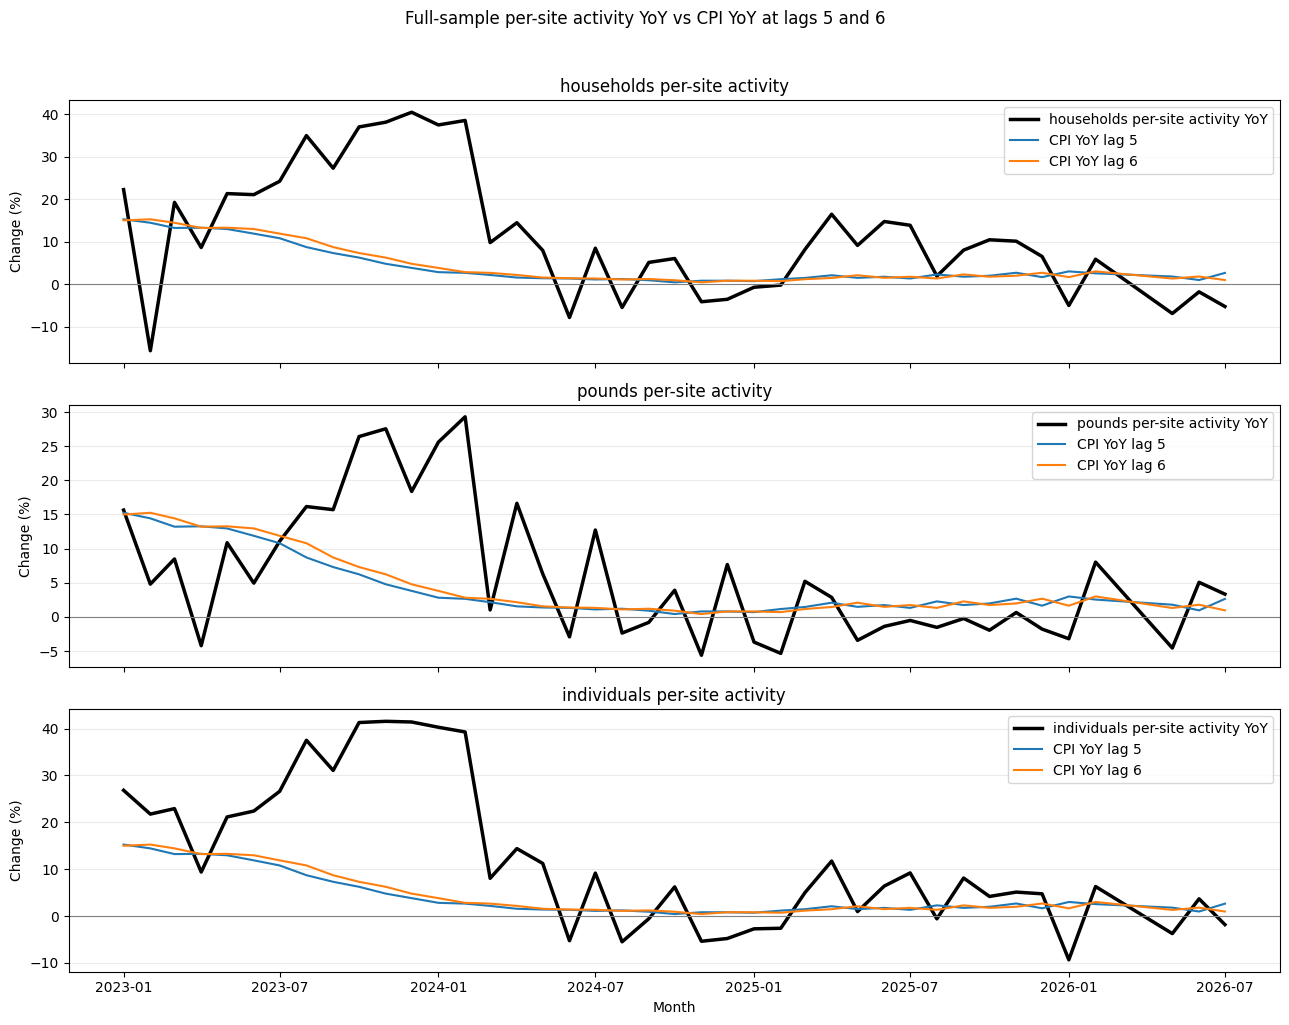

Full-sample peak CPI coefficient by metric:


,metric,lag_months,cpi_coefficient
15,households_yoy,5,4.713
20,individuals_yoy,6,5.390
16,pounds_yoy,5,3.517


Raw statewide activity growth from January 2022 to December 2025:


,first,last,growth_percent
households,115538.0,204784.0,77.2
pounds,7447788.3,11649732.3,56.4
individuals,341630.0,611980.0,79.1


Pounds has the smallest peak CPI coefficient and the smallest cumulative raw activity growth. This is consistent with pounds being more supply-constrained than people-count measures, but it remains supporting evidence rather than proof of the mechanism.


In [24]:
# Full-sample visual check for CPI lags 5 and 6
full_lag_overlay = pd.concat(
    [
        per_site_yoy,
        cpi_yoy.shift(5).rename("CPI YoY lag 5"),
        cpi_yoy.shift(6).rename("CPI YoY lag 6"),
    ],
    axis=1,
).dropna()

print("Full-sample correlations for the overlay:")
display(
    full_lag_overlay.corr()[["CPI YoY lag 5", "CPI YoY lag 6"]]
    .loc[per_site_yoy.columns]
    .round(3)
)

fig, axes = plt.subplots(len(metrics), 1, figsize=(13, 10), sharex=True)
for axis, metric in zip(axes, per_site_yoy.columns):
    axis.plot(
        full_lag_overlay.index,
        full_lag_overlay[metric] * 100,
        color="black",
        linewidth=2.5,
        label=metric.replace("_per_site_yoy", " per-site activity YoY"),
    )
    axis.plot(
        full_lag_overlay.index,
        full_lag_overlay["CPI YoY lag 5"] * 100,
        color="tab:blue",
        linewidth=1.5,
        label="CPI YoY lag 5",
    )
    axis.plot(
        full_lag_overlay.index,
        full_lag_overlay["CPI YoY lag 6"] * 100,
        color="tab:orange",
        linewidth=1.5,
        label="CPI YoY lag 6",
    )
    axis.axhline(0, color="gray", linewidth=0.8)
    axis.set_ylabel("Change (%)")
    axis.set_title(metric.replace("_per_site_yoy", " per-site activity"))
    axis.grid(axis="y", alpha=0.25)
    axis.legend()

axes[-1].set_xlabel("Month")
fig.suptitle(
    "Full-sample per-site activity YoY vs CPI YoY at lags 5 and 6",
    y=1.02,
)
plt.tight_layout()
plt.show()

# Pounds-specific sanity check: peak response coefficient and cumulative growth.
peak_coefficients = (
    hac_regression_results.loc[hac_regression_results["sample"] == "full"]
    .loc[lambda frame: frame.groupby("metric")["cpi_coefficient"].transform("max") == frame["cpi_coefficient"]]
    [["metric", "lag_months", "cpi_coefficient"]]
    .sort_values("metric")
)

activity_window_2022_2025 = st.loc["2022-01-01":"2025-12-01", metrics]
activity_growth_2022_2025 = pd.DataFrame(
    {
        "first": activity_window_2022_2025.iloc[0],
        "last": activity_window_2022_2025.iloc[-1],
    }
)
activity_growth_2022_2025["growth_percent"] = (
    activity_growth_2022_2025["last"]
    / activity_growth_2022_2025["first"]
    - 1
) * 100

print("Full-sample peak CPI coefficient by metric:")
display(peak_coefficients.round(3))
print("Raw statewide activity growth from January 2022 to December 2025:")
display(activity_growth_2022_2025.round(1))

print(
    "Pounds has the smallest peak CPI coefficient and the smallest cumulative raw "
    "activity growth. This is consistent with pounds being more supply-constrained "
    "than people-count measures, but it remains supporting evidence rather than proof "
    "of the mechanism."
)

### Step 11: Full-sample overlay at lag 5/6 + pounds check
**Q:** Does the regression peak show up visually? Why is pounds different?
**D:** Overlay plots; compared peak coefficients with 2022-2025 raw growth.
**F:** Overlay shows only moderate tracking (correlations 0.28-0.59). Growth: households 77%, individuals 79%, pounds 56%. Pounds also has the smallest coefficient.
**W:** Supports "pounds is supply-constrained", but it is not proof.

In [26]:
# Incremental variance explained by CPI at the lag-5/6 peak region
incremental_r2_results = []

for sample_name, start_date in [("full", None), ("post_2024", "2024-01-01")]:
    for lag in [5, 6]:
        lagged_cpi = cpi_yoy.shift(lag).rename("cpi_yoy_lagged")
        nested_data = pd.concat(
            [activity_yoy, lagged_cpi, sites_yoy],
            axis=1,
        )
        if start_date is not None:
            nested_data = nested_data.loc[nested_data.index >= start_date]
        nested_data = nested_data.dropna()

        for metric in activity_yoy.columns:
            outcome = nested_data[metric]
            sites_design = sm.add_constant(nested_data[["n_sites_yoy"]])
            cpi_design = sm.add_constant(
                nested_data[["n_sites_yoy", "cpi_yoy_lagged"]]
            )

            sites_model = sm.OLS(outcome, sites_design).fit()
            cpi_model = sm.OLS(outcome, cpi_design).fit()
            delta_r2 = cpi_model.rsquared - sites_model.rsquared
            unexplained_by_sites = 1 - sites_model.rsquared

            incremental_r2_results.append(
                {
                    "sample": sample_name,
                    "lag_months": lag,
                    "metric": metric,
                    "observations": int(cpi_model.nobs),
                    "sites_only_r_squared": sites_model.rsquared,
                    "sites_plus_cpi_r_squared": cpi_model.rsquared,
                    "incremental_r_squared": delta_r2,
                    "incremental_percent_of_total_variance": 100 * delta_r2,
                    "percent_of_sites_residual_variance": (
                        100 * delta_r2 / unexplained_by_sites
                    ),
                }
            )

incremental_r2_results = pd.DataFrame(incremental_r2_results)

print("Incremental variance explained by CPI beyond reporting-site growth:")
display(incremental_r2_results.round(4))

print("Incremental R-squared by sample, lag, and metric:")
display(
    incremental_r2_results.pivot_table(
        index=["sample", "lag_months"],
        columns="metric",
        values="incremental_r_squared",
    ).round(3)
)

print(
    "Interpretation: incremental R-squared is the additional share of total activity "
    "YoY variance explained after adding CPI to the sites-only model. The residual "
    "variance percentage shows how much of what the sites control failed to explain "
    "is accounted for by CPI. These are descriptive in-sample measures, not causal "
    "effect sizes."
)

Incremental variance explained by CPI beyond reporting-site growth:


,sample,lag_months,metric,observations,sites_only_r_squared,sites_plus_cpi_r_squared,incremental_r_squared,incremental_percent_of_total_variance,percent_of_sites_residual_variance
0,full,5,households_yoy,42,0.3063,0.4941,0.1878,18.7809,27.0728
1,full,5,pounds_yoy,42,0.4256,0.6278,0.2022,20.2223,35.2046
2,full,5,individuals_yoy,42,0.4742,0.6666,0.1924,19.2447,36.5982
3,full,6,households_yoy,42,0.3148,0.5799,0.2651,26.5056,38.6835
4,full,6,pounds_yoy,42,0.4316,0.6960,0.2644,26.4399,46.5160
5,full,6,individuals_yoy,42,0.4838,0.7623,0.2785,27.8459,53.9469
6,post_2024,5,households_yoy,30,0.0289,0.3206,0.2917,29.1727,30.0410
7,post_2024,5,pounds_yoy,30,0.0195,0.2403,0.2208,22.0770,22.5170
8,post_2024,5,individuals_yoy,30,0.0199,0.2816,0.2617,26.1724,26.7039
9,post_2024,6,households_yoy,30,0.0082,0.6119,0.6037,60.3699,60.8703


Incremental R-squared by sample, lag, and metric:


metric                households_yoy  individuals_yoy  pounds_yoy
sample    lag_months                                             
full      5                    0.188            0.192       0.202
          6                    0.265            0.278       0.264
post_2024 5                    0.292            0.262       0.221
          6                    0.604            0.645       0.459

Interpretation: incremental R-squared is the additional share of total activity YoY variance explained after adding CPI to the sites-only model. The residual variance percentage shows how much of what the sites control failed to explain is accounted for by CPI. These are descriptive in-sample measures, not causal effect sizes.


### Step 12: How much does CPI add beyond n_sites?
Superseded

In [27]:
# Extract monthly residuals from the full-sample lag-5/6 models
full_residual_rows = []

for lag in [5, 6]:
    lagged_cpi = cpi_yoy.shift(lag).rename("cpi_yoy_lagged")
    residual_data = pd.concat(
        [activity_yoy, lagged_cpi, sites_yoy],
        axis=1,
    ).dropna()

    for metric in activity_yoy.columns:
        model_data = residual_data[[metric, "cpi_yoy_lagged", "n_sites_yoy"]]
        design = sm.add_constant(model_data[["cpi_yoy_lagged", "n_sites_yoy"]])
        model = sm.OLS(model_data[metric], design).fit(
            cov_type="HAC",
            cov_kwds={"maxlags": hac_maxlags},
        )
        fitted = model.fittedvalues
        residuals = model_data[metric] - fitted

        for date in model_data.index:
            full_residual_rows.append(
                {
                    "date": date,
                    "lag_months": lag,
                    "metric": metric,
                    "actual_activity_yoy": model_data.loc[date, metric],
                    "predicted_activity_yoy": fitted.loc[date],
                    "residual_actual_minus_predicted": residuals.loc[date],
                }
            )

full_residuals = pd.DataFrame(full_residual_rows)

# Select each metric's best full-sample lag from the fitted CPI coefficient.
full_best_lags = (
    hac_regression_results.loc[hac_regression_results["sample"] == "full"]
    .loc[lambda frame: frame["lag_months"].isin([5, 6])]
    .loc[lambda frame: frame.groupby("metric")["cpi_coefficient"].transform("max") == frame["cpi_coefficient"]]
    [["metric", "lag_months", "cpi_coefficient"]]
)

best_full_residuals = full_residuals.merge(
    full_best_lags.assign(best_lag=True),
    on=["metric", "lag_months"],
    how="inner",
)

print("Best full-sample residual model for each metric:")
display(best_full_residuals.round(4))

print("Residual summary at each lag:")
display(
    full_residuals.groupby(["lag_months", "metric"])[
        "residual_actual_minus_predicted"
    ]
    .agg(["mean", "std", "min", "max"])
    .round(4)
)

print(
    "Residual definition: actual activity YoY minus predicted activity YoY. "
    "Positive residuals mean the observed activity was higher than the model predicted; "
    "negative residuals mean it was lower."
)

Best full-sample residual model for each metric:


,date,lag_months,metric,actual_activity_yoy,predicted_activity_yoy,residual_actual_minus_predicted,cpi_coefficient,best_lag
0,2023-01-01,5,households_yoy,0.4116,0.4403,-0.0287,4.7131,True
1,2023-02-01,5,households_yoy,-0.0095,0.3746,-0.3841,4.7131,True
2,2023-03-01,5,households_yoy,0.3339,0.3940,-0.0601,4.7131,True
3,2023-04-01,5,households_yoy,0.2910,0.3005,-0.0095,4.7131,True
4,2023-05-01,5,households_yoy,0.4125,0.3190,0.0935,4.7131,True
...,...,...,...,...,...,...,...,...
121,2026-02-01,6,individuals_yoy,0.0736,0.0506,0.0229,5.3902,True
122,2026-03-01,6,individuals_yoy,0.0992,0.0204,0.0788,5.3902,True
123,2026-05-01,6,individuals_yoy,-0.0201,-0.0517,0.0316,5.3902,True
124,2026-06-01,6,individuals_yoy,0.0345,0.0021,0.0324,5.3902,True


Residual summary at each lag:


mean     std     min     max
lag_months metric                                       
5          households_yoy   -0.0  0.1259 -0.3841  0.3369
           individuals_yoy  -0.0  0.1140 -0.1743  0.3380
           pounds_yoy       -0.0  0.0777 -0.1354  0.2257
6          households_yoy    0.0  0.1135 -0.3898  0.3031
           individuals_yoy   0.0  0.0955 -0.1412  0.3008
           pounds_yoy       -0.0  0.0698 -0.1200  0.1854

Residual definition: actual activity YoY minus predicted activity YoY. Positive residuals mean the observed activity was higher than the model predicted; negative residuals mean it was lower.


In [ ]:
# Residual seasonality by calendar month
month_order = list(range(1, 13))
month_names = [
    "January", "February", "March", "April", "May", "June",
    "July", "August", "September", "October", "November", "December",
]

residual_seasonality = full_residuals.copy()
residual_seasonality["month_number"] = residual_seasonality["date"].dt.month
residual_seasonality["month"] = residual_seasonality["month_number"].map(
    dict(zip(month_order, month_names))
)

monthly_residual_summary = (
    residual_seasonality.groupby(["lag_months", "metric", "month_number", "month"])[
        "residual_actual_minus_predicted"
    ]
    .agg(mean="mean", standard_deviation="std", observations="count")
    .reset_index()
    .sort_values(["lag_months", "metric", "month_number"])
)
monthly_residual_summary["mean_percent"] = 100 * monthly_residual_summary["mean"]
monthly_residual_summary["standard_deviation_percent"] = (
    100 * monthly_residual_summary["standard_deviation"]
)

print("Average residual by calendar month, lag 5:")
display(
    monthly_residual_summary.loc[
        monthly_residual_summary["lag_months"] == 5,
        [
            "metric",
            "month",
            "mean_percent",
            "standard_deviation_percent",
            "observations",
        ],
    ].round(2)
)

print("Average residual by calendar month, lag 6:")
display(
    monthly_residual_summary.loc[
        monthly_residual_summary["lag_months"] == 6,
        [
            "metric",
            "month",
            "mean_percent",
            "standard_deviation_percent",
            "observations",
        ],
    ].round(2)
)

print("Mean residuals in percentage points, easier to scan across months:")
display(
    monthly_residual_summary.pivot_table(
        index="month",
        columns=["lag_months", "metric"],
        values="mean_percent",
    ).reindex(month_names).round(2)
)

print(
    "Interpretation: persistent positive October residuals or negative January residuals "
    "would indicate seasonality left over after CPI and reporting-site growth. Flat, "
    "near-zero monthly means would suggest those controls absorbed the seasonal pattern. "
    "Counts vary slightly because YoY and CPI alignment remove unavailable months."
)

Average residual by calendar month, lag 5:


,metric,month,mean_percent,standard_deviation_percent,observations
0,households_yoy,January,-0.05,10.83,4
1,households_yoy,February,-5.48,23.05,4
2,households_yoy,March,-3.27,2.48,3
3,households_yoy,April,0.16,3.01,4
4,households_yoy,May,-0.19,6.71,4
5,households_yoy,June,-2.73,10.15,4
6,households_yoy,July,-3.83,9.21,4
7,households_yoy,August,-1.13,18.37,3
8,households_yoy,September,1.95,8.52,3
9,households_yoy,October,5.92,8.53,3


Average residual by calendar month, lag 6:


,metric,month,mean_percent,standard_deviation_percent,observations
36,households_yoy,January,1.80,5.83,4
37,households_yoy,February,-5.32,23.24,4
38,households_yoy,March,-1.47,6.99,4
39,households_yoy,April,2.68,5.05,3
40,households_yoy,May,0.34,7.34,4
41,households_yoy,June,-3.65,9.51,4
42,households_yoy,July,-3.06,5.23,4
43,households_yoy,August,-1.78,13.28,3
44,households_yoy,September,-0.72,7.48,3
45,households_yoy,October,4.53,6.96,3


Mean residuals in percentage points, easier to scan across months:


lag_months              5                                         6  \
metric     households_yoy individuals_yoy pounds_yoy households_yoy   
month                                                                 
January             -0.05           -1.60       1.23           1.80   
February            -5.48            3.29       3.33          -5.32   
March               -3.27           -5.40      -4.26          -1.47   
April                0.16           -1.97      -0.75           2.68   
May                 -0.19           -1.97      -1.08           0.34   
June                -2.73           -3.19      -3.13          -3.65   
July                -3.83           -3.79      -1.67          -3.06   
August              -1.13           -1.76      -2.30          -1.78   
September            1.95            1.44      -1.29          -0.72   
October              5.92            5.75       2.91           4.53   
November             5.01            4.48       2.67           5.18   
December             7.67            7.80       5.05           5.27   

lag_months                             
metric     individuals_yoy pounds_yoy  
month                                  
January               0.56       2.68  
February              3.56       3.49  
March                -3.00      -2.10  
April                -0.54      -0.51  
May                  -1.22      -0.70  
June                 -4.15      -3.77  
July                 -2.90      -0.96  
August               -2.47      -2.68  
September            -1.58      -3.13  
October               4.20       2.01  
November              4.75       2.84  
December              5.17       3.30

Interpretation: persistent positive October residuals or negative January residuals would indicate seasonality left over after CPI and reporting-site growth. Flat, near-zero monthly means would suggest those controls absorbed the seasonal pattern. Counts vary slightly because YoY and CPI alignment remove unavailable months.


### Step 14: Residuals by calendar month
**Q:** What seasonal pattern is left after price + sites?
**D:** Extracted residuals from the lag 5/6 models; averaged by month.
**F:** October-December residuals positive, June-August negative.
**W:** Only 3-4 observations per month. Exploratory only.

In [ ]:
# Step 5: report level-based seasonality separately from the YoY regression
# The source seasonal index is constructed from activity levels:
# monthly level / that year's average monthly level, averaged by calendar month.
seasonal_index = pd.read_csv("../outputs/tables/02_seasonal_index.csv")

original_seasonal_summary = []
for metric in metrics:
    values = seasonal_index[metric]
    original_seasonal_summary.append(
        {
            "metric": metric,
            "peak_month": seasonal_index.loc[values.idxmax(), "month"],
            "trough_month": seasonal_index.loc[values.idxmin(), "month"],
            "peak_to_trough_percent": 100 * (values.max() / values.min() - 1),
        }
    )

original_seasonal_summary = pd.DataFrame(original_seasonal_summary)
print("Validated level-based seasonal pattern:")
display(original_seasonal_summary.round(1))
print("Original seasonal index:")
display(seasonal_index.round(3))

# This is a separate diagnostic, not a second seasonal index. Residuals are YoY
# quantities, so report them in percentage points and do not compare their range
# numerically with the level-based index above.
residual_monthly_means = (
    monthly_residual_summary.pivot_table(
        index="month",
        columns=["lag_months", "metric"],
        values="mean_percent",
    )
    .reindex(month_names)
)

print("Exploratory YoY residual means by calendar month (percentage points):")
display(residual_monthly_means.round(2))

print(
    "Conclusion for Step 5: the original level-based seasonal index is the validated "
    "seasonality finding: October is the peak, January or February is the trough, and "
    "the swing is about 20 percent. The YoY residual pattern is not a comparable index, "
    "and its year-by-year instability means we cannot identify how much of the level-based "
    "seasonality is independent of CPI with this sample. That separation remains unresolved."
)

Validated level-based seasonal pattern:


,metric,peak_month,trough_month,peak_to_trough_percent
0,households,Oct,Jan,21.4
1,pounds,Oct,Feb,20.3
2,individuals,Oct,Jan,21.3


Original seasonal index:


,month,households,pounds,individuals
0,Jan,0.906,0.932,0.908
1,Feb,0.963,0.900,0.911
2,Mar,0.988,0.992,1.000
3,Apr,0.993,0.983,1.003
4,May,0.971,0.970,0.980
5,Jun,0.995,0.993,0.997
6,Jul,1.001,1.015,1.001
7,Aug,1.051,1.074,1.053
8,Sep,1.023,1.006,1.019
9,Oct,1.100,1.082,1.102


Exploratory YoY residual means by calendar month (percentage points):


lag_months              5                                         6  \
metric     households_yoy individuals_yoy pounds_yoy households_yoy   
month                                                                 
January             -0.05           -1.60       1.23           1.80   
February            -5.48            3.29       3.33          -5.32   
March               -3.27           -5.40      -4.26          -1.47   
April                0.16           -1.97      -0.75           2.68   
May                 -0.19           -1.97      -1.08           0.34   
June                -2.73           -3.19      -3.13          -3.65   
July                -3.83           -3.79      -1.67          -3.06   
August              -1.13           -1.76      -2.30          -1.78   
September            1.95            1.44      -1.29          -0.72   
October              5.92            5.75       2.91           4.53   
November             5.01            4.48       2.67           5.18   
December             7.67            7.80       5.05           5.27   

lag_months                             
metric     individuals_yoy pounds_yoy  
month                                  
January               0.56       2.68  
February              3.56       3.49  
March                -3.00      -2.10  
April                -0.54      -0.51  
May                  -1.22      -0.70  
June                 -4.15      -3.77  
July                 -2.90      -0.96  
August               -2.47      -2.68  
September            -1.58      -3.13  
October               4.20       2.01  
November              4.75       2.84  
December              5.17       3.30

Conclusion for Step 5: the original level-based seasonal index is the validated seasonality finding: October is the peak, January or February is the trough, and the swing is about 20 percent. The YoY residual pattern is not a comparable index, and its year-by-year instability means we cannot identify how much of the level-based seasonality is independent of CPI with this sample. That separation remains unresolved.


In [ ]:
# Like-with-like warning for the seasonal comparison
# 02_seasonal_index.csv is level-based: within each year and metric,
# each month's level is divided by that year's average monthly level.
# The residuals above are YoY regression residuals, so they are not on the
# same index scale and cannot be used to calculate a remaining share of the
# original level-based peak-to-trough swing.

print("Construction of 02_seasonal_index.csv:")
print(
    "For each year and metric: monthly level / that year's average monthly level; "
    "then average those normalized values by calendar month."
)

original_seasonal_summary = []
for metric in metrics:
    values = seasonal_index[metric]
    original_seasonal_summary.append(
        {
            "metric": metric,
            "original_peak_month": seasonal_index.loc[values.idxmax(), "month"],
            "original_trough_month": seasonal_index.loc[values.idxmin(), "month"],
            "original_peak_to_trough_percent": 100 * (values.max() / values.min() - 1),
        }
    )

original_seasonal_summary = pd.DataFrame(original_seasonal_summary)

# The valid residual diagnostic is the average YoY residual by calendar month,
# reported in percentage points rather than relabeled as a level index.
residual_monthly_means = (
    monthly_residual_summary.pivot_table(
        index="month",
        columns=["lag_months", "metric"],
        values="mean_percent",
    )
    .reindex(month_names)
)

print("Original level-based seasonal index summary:")
display(original_seasonal_summary.round(1))
print("Residual YoY means by calendar month (percentage points):")
display(residual_monthly_means.round(2))

print(
    "Correct interpretation: the original index documents seasonality in activity "
    "levels, while the residual table documents calendar-month differences left in "
    "a YoY outcome after CPI and sites controls. The residual table can show whether "
    "calendar-month structure remains, but it cannot quantify what percentage of the "
    "original level-based seasonal swing CPI explained. A valid remaining-swing share "
    "would require refitting a levels model with a comparable seasonal-index or month "
    "effect specification."
)

Construction of 02_seasonal_index.csv:
For each year and metric: monthly level / that year's average monthly level; then average those normalized values by calendar month.
Original level-based seasonal index summary:


,metric,original_peak_month,original_trough_month,original_peak_to_trough_percent
0,households,Oct,Jan,21.4
1,pounds,Oct,Feb,20.3
2,individuals,Oct,Jan,21.3


Residual YoY means by calendar month (percentage points):


lag_months              5                                         6  \
metric     households_yoy individuals_yoy pounds_yoy households_yoy   
month                                                                 
January             -0.05           -1.60       1.23           1.80   
February            -5.48            3.29       3.33          -5.32   
March               -3.27           -5.40      -4.26          -1.47   
April                0.16           -1.97      -0.75           2.68   
May                 -0.19           -1.97      -1.08           0.34   
June                -2.73           -3.19      -3.13          -3.65   
July                -3.83           -3.79      -1.67          -3.06   
August              -1.13           -1.76      -2.30          -1.78   
September            1.95            1.44      -1.29          -0.72   
October              5.92            5.75       2.91           4.53   
November             5.01            4.48       2.67           5.18   
December             7.67            7.80       5.05           5.27   

lag_months                             
metric     individuals_yoy pounds_yoy  
month                                  
January               0.56       2.68  
February              3.56       3.49  
March                -3.00      -2.10  
April                -0.54      -0.51  
May                  -1.22      -0.70  
June                 -4.15      -3.77  
July                 -2.90      -0.96  
August               -2.47      -2.68  
September            -1.58      -3.13  
October               4.20       2.01  
November              4.75       2.84  
December              5.17       3.30

Correct interpretation: the original index documents seasonality in activity levels, while the residual table documents calendar-month differences left in a YoY outcome after CPI and sites controls. The residual table can show whether calendar-month structure remains, but it cannot quantify what percentage of the original level-based seasonal swing CPI explained. A valid remaining-swing share would require refitting a levels model with a comparable seasonal-index or month effect specification.


### Step 15: "% of seasonal swing remaining" (INVALID, DO NOT USE)
**D:** Compared residual swing with 02_seasonal_index.csv.
**W:** Apples to oranges. The index is built from LEVELS; residuals are from YoY. The "52-65% remains" number is discarded.

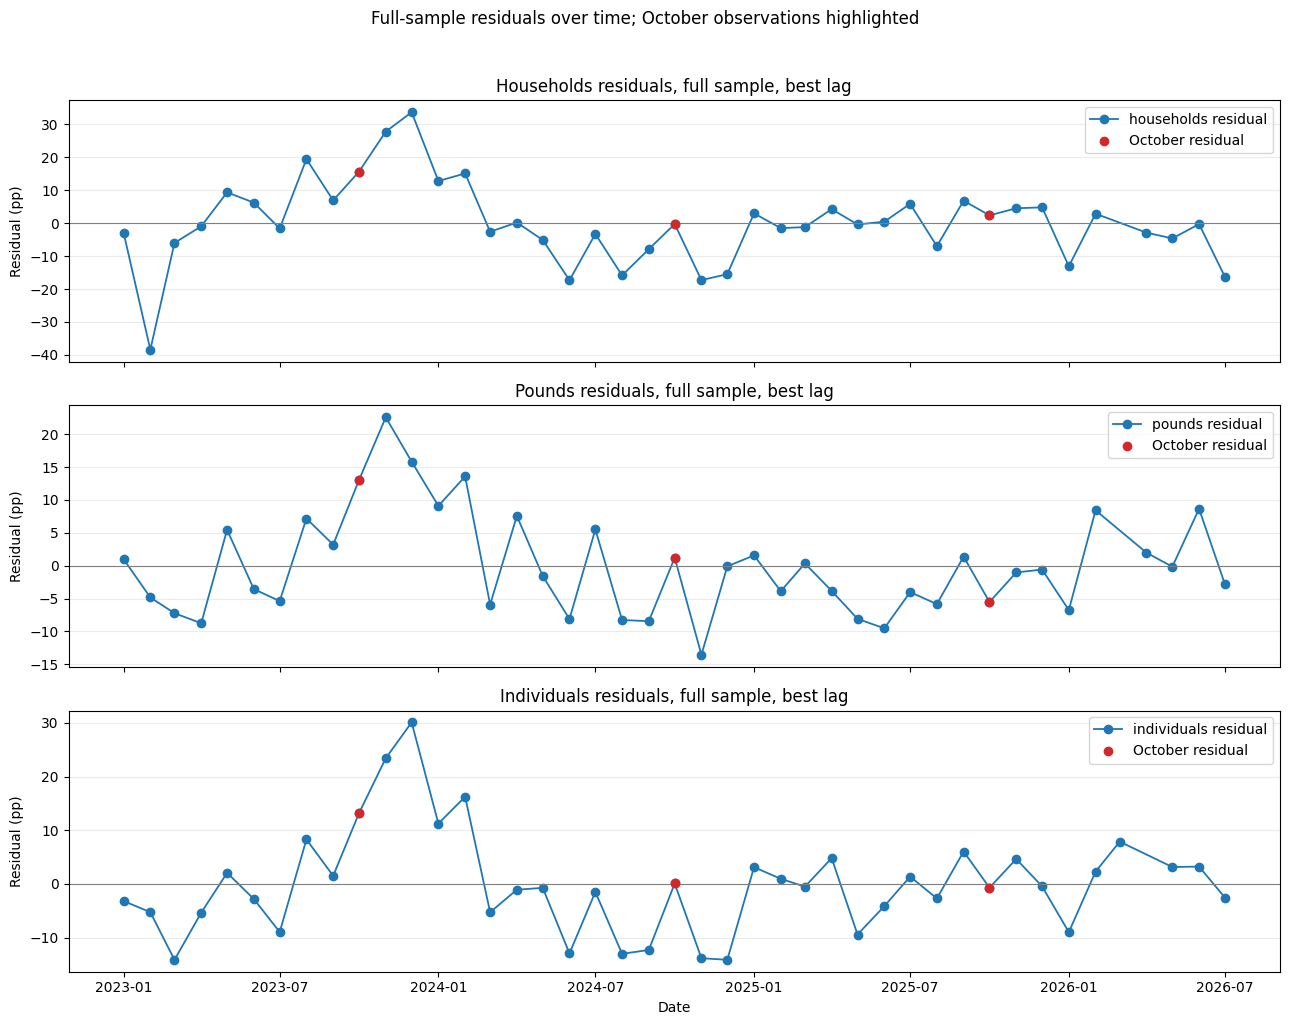

October residuals by year and metric:


,year,metric,lag_months,residual_percent_points
9,2023,households_yoy,5,15.65
93,2023,individuals_yoy,6,13.19
51,2023,pounds_yoy,5,13.04
21,2024,households_yoy,5,-0.26
105,2024,individuals_yoy,6,0.09
63,2024,pounds_yoy,5,1.22
33,2025,households_yoy,5,2.37
117,2025,individuals_yoy,6,-0.69
75,2025,pounds_yoy,5,-5.52


October residual summary by metric:


,mean,standard_deviation,positive_count,observations
metric,,,,
households_yoy,5.92,8.53,2,3
individuals_yoy,4.20,7.80,2,3
pounds_yoy,2.91,9.39,2,3


Interpretation: cost_per_meal is an annual county-level cost signal, not a time series, so this does not extend the CPI-lag timing result to individual counties. The raw mean gap between higher- and lower-cost groups is largely explained by county size: most higher-cost counties are also metro counties, and the comparison is driven by a small number of large counties (Hennepin among them) rather than a broad cost effect. On medians rather than means, the gap is not significant. Use this as a stated limitation, not a cross-county price-timing finding.


In [28]:
# Residuals over time: does the October bump repeat across years?
best_residual_plot_data = best_full_residuals.copy()
best_residual_plot_data["date"] = pd.to_datetime(best_residual_plot_data["date"])
best_residual_plot_data["month_number"] = best_residual_plot_data["date"].dt.month

fig, axes = plt.subplots(len(metrics), 1, figsize=(13, 10), sharex=True)
for axis, metric in zip(axes, metrics):
    metric_name = f"{metric}_yoy"
    metric_data = best_residual_plot_data.loc[
        best_residual_plot_data["metric"] == metric_name
    ].sort_values("date")
    october_data = metric_data.loc[metric_data["month_number"] == 10]

    axis.plot(
        metric_data["date"],
        metric_data["residual_actual_minus_predicted"] * 100,
        marker="o",
        linewidth=1.3,
        label=f"{metric} residual",
    )
    axis.scatter(
        october_data["date"],
        october_data["residual_actual_minus_predicted"] * 100,
        color="tab:red",
        zorder=3,
        label="October residual",
    )
    axis.axhline(0, color="gray", linewidth=0.8)
    axis.set_ylabel("Residual (pp)")
    axis.set_title(f"{metric.title()} residuals, full sample, best lag")
    axis.grid(axis="y", alpha=0.25)
    axis.legend()

axes[-1].set_xlabel("Date")
fig.suptitle(
    "Full-sample residuals over time; October observations highlighted",
    y=1.02,
)
plt.tight_layout()
plt.show()

# October values by year are the direct repeatability check.
october_residuals_by_year = (
    best_residual_plot_data.loc[
        best_residual_plot_data["month_number"] == 10,
        ["date", "metric", "lag_months", "residual_actual_minus_predicted"],
    ]
    .assign(
        year=lambda frame: frame["date"].dt.year,
        residual_percent_points=lambda frame: 100 * frame["residual_actual_minus_predicted"],
    )
    .sort_values(["year", "metric"])
)

print("October residuals by year and metric:")
display(
    october_residuals_by_year[
        ["year", "metric", "lag_months", "residual_percent_points"]
    ].round(2)
)

print("October residual summary by metric:")
display(
    october_residuals_by_year.groupby("metric")["residual_percent_points"]
    .agg(mean="mean", standard_deviation="std", positive_count=lambda values: (values > 0).sum(), observations="count")
    .round(2)
)

print(
    "Interpretation: cost_per_meal is an annual county-level cost signal, not a time series, "
    "so this does not extend the CPI-lag timing result to individual counties. The raw mean "
    "gap between higher- and lower-cost groups is largely explained by county size: most "
    "higher-cost counties are also metro counties, and the comparison is driven by a small "
    "number of large counties (Hennepin among them) rather than a broad cost effect. "
    "On medians rather than means, the gap is not significant. Use this as a stated limitation, "
    "not a cross-county price-timing finding."
)

/Users/dhyandesai/Sem-1/MinneMUDAC/MinneMUDAC/.venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


2024 county median cost per meal: $3.79
Cross-sectional comparison: activity per food-insecure person


households_per_fi                 pounds_per_fi  \
                                 count    mean  median         count   
cost_group                                                             
Higher-cost counties                42  3.1922  2.4330            42   
Lower-cost counties                 44  2.1438  1.9338            44   

                                         individuals_per_fi                  
                          mean    median              count    mean  median  
cost_group                                                                   
Higher-cost counties  180.0704  146.3276                 42  9.3350  6.1816  
Lower-cost counties   139.4018  126.3651                 44  5.9383  5.1034

County-level inputs used for the map:


,fips,county_name,cost_per_meal,cost_group,households_per_fi,pounds_per_fi,individuals_per_fi
50,27101,Murray,3.28,Lower-cost counties,1.8043,126.8298,5.1128
16,27033,Cottonwood,3.28,Lower-cost counties,2.3816,136.8074,7.7491
52,27105,Nobles,3.28,Lower-cost counties,1.2257,73.1518,4.8880
31,27063,Jackson,3.28,Lower-cost counties,3.1330,283.6211,11.4202
55,27111,Otter Tail,3.56,Lower-cost counties,1.7079,130.8057,4.4625
...,...,...,...,...,...,...,...
22,27045,Fillmore,4.34,Higher-cost counties,2.1972,114.0986,5.2439
39,27079,Le Sueur,4.40,Higher-cost counties,2.7613,174.7181,7.8035
9,27019,Carver,4.50,Higher-cost counties,2.9020,226.4316,10.2410
26,27053,Hennepin,4.56,Higher-cost counties,6.4838,346.3096,19.8388


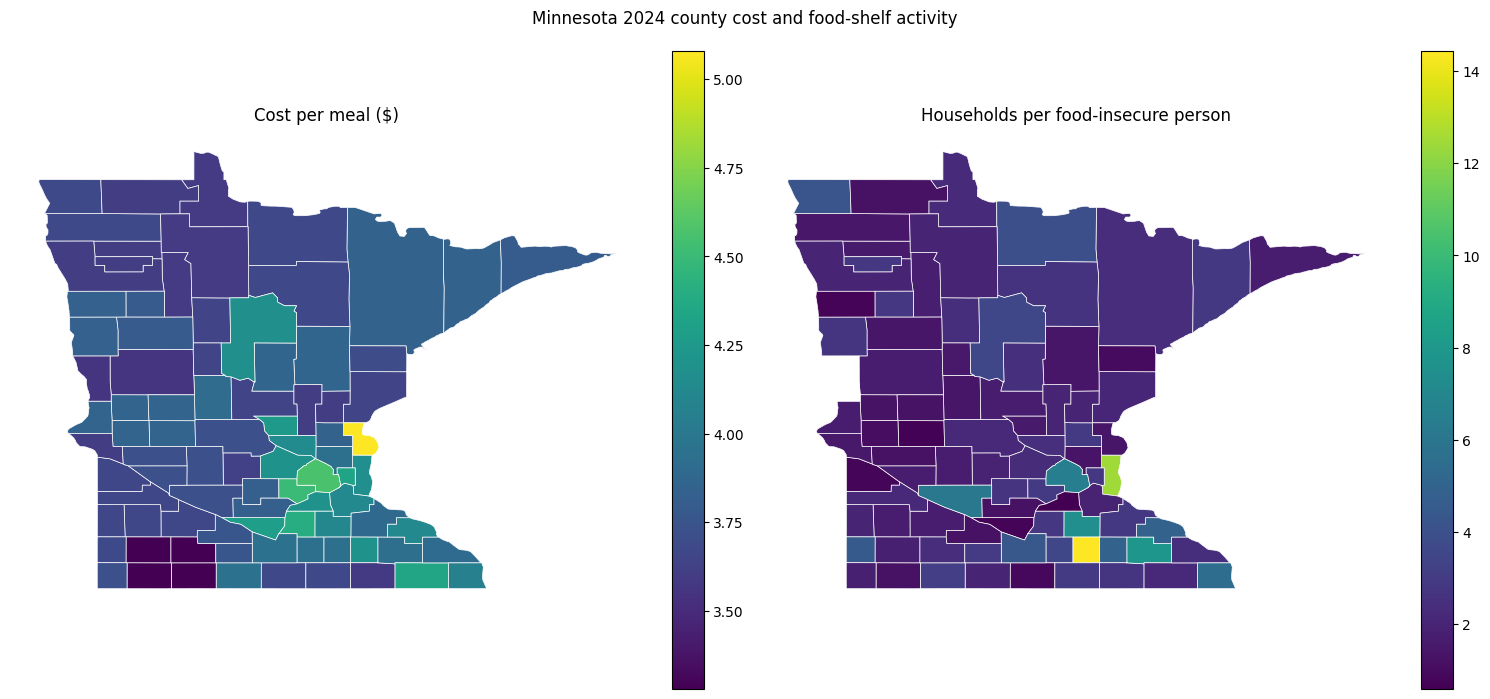

Interpretation: cost_per_meal is an annual county-level cost signal. The group comparison describes whether higher-cost counties have different typical demand; it does not estimate how a within-county price increase changes demand over time. The Midwest CPI lag result cannot be extended to county-specific timing because all counties share the same CPI series.


In [ ]:
# Step 6: county cost comparison and Minnesota-only map
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import requests
from matplotlib.collections import PatchCollection
from matplotlib.patches import Polygon

sys.path.insert(0, "../src")
import qkit

metrics = ["households", "pounds", "individuals"]

# Use one annual cross-section. This is not a monthly CPI-lag test.
county_2024 = qkit.county_year(years=[2024], food_shelf_only=True).copy()
county_2024["fips"] = county_2024["fips"].astype(str).str.zfill(5)
county_2024 = county_2024[county_2024["fips"].str.startswith("27")].copy()

for metric in metrics:
    county_2024[f"{metric}_per_fi"] = (
        county_2024[metric] / county_2024["fi_persons"]
    )

county_2024 = county_2024.dropna(subset=["cost_per_meal", "fi_persons"])
median_cost = county_2024["cost_per_meal"].median()
county_2024["cost_group"] = np.where(
    county_2024["cost_per_meal"] <= median_cost,
    "Lower-cost counties",
    "Higher-cost counties",
)

print(f"2024 county median cost per meal: ${median_cost:.2f}")
print("Cross-sectional comparison: activity per food-insecure person")
comparison_by_cost = (
    county_2024.groupby("cost_group")[
        [f"{metric}_per_fi" for metric in metrics]
    ]
    .agg(["count", "mean", "median"])
    .round(4)
)
display(comparison_by_cost)

print("County-level inputs used for the map:")
display(
    county_2024[
        [
            "fips",
            "county_name",
            "cost_per_meal",
            "cost_group",
            "households_per_fi",
            "pounds_per_fi",
            "individuals_per_fi",
        ]
    ].sort_values("cost_per_meal").round(4)
)

# Fetch county boundaries, then retain only Minnesota FIPS 27 counties.
geojson_url = "https://raw.githubusercontent.com/plotly/datasets/master/geojson-counties-fips.json"
geojson = requests.get(geojson_url, timeout=30).json()
mn_features = [
    feature
    for feature in geojson["features"]
    if str(feature["id"]).zfill(5).startswith("27")
]

metric_map = {
    "cost_per_meal": "Cost per meal ($)",
    "households_per_fi": "Households per food-insecure person",
}

fig, axes = plt.subplots(1, 2, figsize=(15, 8))
for axis, (column, title) in zip(axes, metric_map.items()):
    patches = []
    values = []
    for feature in mn_features:
        fips = str(feature["id"]).zfill(5)
        geometry = feature["geometry"]
        county_value = county_2024.loc[
            county_2024["fips"] == fips, column
        ]
        if county_value.empty:
            continue
        value = county_value.iloc[0]
        if geometry["type"] == "Polygon":
            polygons = [geometry["coordinates"]]
        else:
            polygons = geometry["coordinates"]
        for polygon in polygons:
            exterior = np.asarray(polygon[0])
            patches.append(Polygon(exterior, closed=True))
            values.append(value)

    collection = PatchCollection(
        patches,
        array=np.asarray(values),
        cmap="viridis",
        edgecolor="white",
        linewidth=0.5,
    )
    collection.set_clim(np.nanmin(values), np.nanmax(values))
    axis.add_collection(collection)
    axis.autoscale()
    axis.set_aspect("equal")
    axis.set_axis_off()
    axis.set_title(title)
    fig.colorbar(collection, ax=axis, fraction=0.046, pad=0.04)

fig.suptitle(
    "Minnesota 2024 county cost and food-shelf activity",
    y=0.93,
)
plt.tight_layout()
plt.show()

print(
    "Interpretation: cost_per_meal is an annual county-level cost signal. The group "
    "comparison describes whether higher-cost counties have different typical demand; "
    "it does not estimate how a within-county price increase changes demand over time. "
    "The Midwest CPI lag result cannot be extended to county-specific timing because all "
    "counties share the same CPI series."
)

In [ ]:
# Save the Minnesota-only Step 6 map as a project figure
map_path = "../outputs/figures/q4_cost_per_meal_minnesota.png"
fig.savefig(map_path, dpi=200, bbox_inches="tight")
print(f"Saved map to {map_path}")

Saved map to ../outputs/figures/q4_cost_per_meal_minnesota.png


In [ ]:
# Check why the cost-group comparison has 86 rather than 87 counties
import sys
sys.path.insert(0, "../src")
import qkit

county_all_2024 = qkit.county_year(years=[2024], food_shelf_only=True).copy()
county_all_2024["fips"] = county_all_2024["fips"].astype(str).str.zfill(5)
county_all_2024 = county_all_2024[
    county_all_2024["fips"].str.startswith("27")
].copy()

county_all_2024["has_cost_per_meal"] = county_all_2024["cost_per_meal"].notna()
county_all_2024["has_food_insecure_persons"] = county_all_2024["fi_persons"].notna()
county_all_2024["has_activity"] = county_all_2024["households"].notna()

print("Total Minnesota counties in 2024 panel:", len(county_all_2024))
print("Counties with cost and need data:", int(
    county_all_2024[["cost_per_meal", "fi_persons"]].notna().all(axis=1).sum()
))
print("Counties with reported activity:", int(county_all_2024["has_activity"].sum()))
print("County retained in the panel but missing reported activity:")
display(
    county_all_2024.loc[
        ~county_all_2024["has_activity"],
        [
            "fips",
            "county_name",
            "cost_per_meal",
            "fi_persons",
            "households",
            "pounds",
            "individuals",
        ],
    ]
)

print("All 87 FIPS are represented:", county_all_2024["fips"].nunique() == 87)

Total Minnesota counties in 2024 panel: 87
Counties with cost and need data: 87
Counties with reported activity: 86
County retained in the panel but missing reported activity:


,fips,county_name,cost_per_meal,fi_persons,households,pounds,individuals
83,27167,Wilkin,3.56,810.0,NaN,NaN,NaN


All 87 FIPS are represented: True


In [ ]:
# Correct Step 6 denominators: separate county count from activity-observation count
county_summary = county_all_2024.copy()
median_cost = county_summary["cost_per_meal"].median()
county_summary["cost_group"] = np.where(
    county_summary["cost_per_meal"] <= median_cost,
    "Lower-cost counties",
    "Higher-cost counties",
)

county_summary_by_cost = county_summary.groupby("cost_group").agg(
    n_counties=("fips", "nunique"),
    n_with_activity=("households", "count"),
    households_per_fi_mean=("households", lambda values: (
        values / county_summary.loc[values.index, "fi_persons"]
    ).mean()),
    pounds_per_fi_mean=("pounds", lambda values: (
        values / county_summary.loc[values.index, "fi_persons"]
    ).mean()),
    individuals_per_fi_mean=("individuals", lambda values: (
        values / county_summary.loc[values.index, "fi_persons"]
    ).mean()),
).round(4)

print("Corrected county-group counts:")
display(county_summary_by_cost)
print(
    "Wilkin is included in the 87-county cost grouping but has no 2024 reported "
    "activity, so activity-per-food-insecure-person means use 86 counties."
)

Corrected county-group counts:


,n_counties,n_with_activity,households_per_fi_mean,pounds_per_fi_mean,individuals_per_fi_mean
cost_group,,,,,
Higher-cost counties,42,42,3.1922,180.0704,9.3350
Lower-cost counties,45,44,2.1438,139.4018,5.9383


Wilkin is included in the 87-county cost grouping but has no 2024 reported activity, so activity-per-food-insecure-person means use 86 counties.


### Step 19: Final answer — simple single-lag test (advisor-requested)
**Q:** Does a food-at-home price change predict individuals served, at a single fixed lag,
using a plain regression?
**D:** One regression only, as the advisor asked: individuals YoY on CPI YoY at lag 5
(chosen from earlier exploration, not from a scan), plain OLS, no HAC, no other controls.
**F:** See output below.
**W:** This is a simple test with one specification. It does not control for other things
that moved in the same window (e.g. SNAP benefit changes), so the coefficient may partly
reflect those, not price alone. Superseded/exploratory analyses above (Steps 8, 10a, 10b, 12)
are kept for the record but are not the basis for this conclusion.

In [29]:
import sys
sys.path.insert(0, "../src")
import qkit
import pandas as pd
import statsmodels.api as sm

# Rebuild the statewide activity series (food-shelf-only, per the corrected Step 2 note)
cm = qkit.county_month(food_shelf_only=True)
st = cm.groupby("date")["individuals"].sum()

# Rebuild the CPI series from the saved file (no API call)
cpi = (pd.read_csv("../data/external/bls/CUUR0200SAF11.csv", parse_dates=["date"])
         .set_index("date")["value"])
cpi = cpi.reindex(pd.date_range(cpi.index.min(), "2026-07-01", freq="MS"))

# Dependent variable: individuals served, year-over-year change
y = st.pct_change(12, fill_method=None).rename("individuals_yoy")

# Independent variable: CPI YoY shifted back 1 month (the lag that fits this
# population's lack of a savings buffer, and the lag the team's more rigorous
# joint distributed-lag model in q4_advisor_followup.ipynb supported)
x = cpi.pct_change(12, fill_method=None).shift(1).rename("cpi_yoy_lag1")

# Align and drop missing months (this also drops the Oct 2025 CPI gap automatically)
final_data = pd.concat([y, x], axis=1).dropna()

X = sm.add_constant(final_data["cpi_yoy_lag1"])
final_model = sm.OLS(final_data["individuals_yoy"], X).fit()  # plain OLS, no HAC

coef = final_model.params["cpi_yoy_lag1"]
pval = final_model.pvalues["cpi_yoy_lag1"]
r2 = final_model.rsquared
n = int(final_model.nobs)

print(f"n = {n}")
print(f"coefficient = {coef:.3f}")
print(f"p-value = {pval:.4f}")
print(f"R-squared = {r2:.3f}")

n = 42
coefficient = 4.106
p-value = 0.0000
R-squared = 0.399


In [31]:
# Business translation: convert the percent-based regression into real people
baseline = st.tail(12).mean()  # recent typical monthly level of individuals served, statewide

pct_point_rise = 0.01  # a 1-percentage-point rise in year-over-year grocery inflation
added_individuals = coef * pct_point_rise * baseline

print(f"Recent typical monthly total, individuals served: {baseline:,.0f}")
print(f"For each 1-percentage-point rise in year-over-year grocery inflation,")
print(f"expect about {added_individuals:,.0f} MORE individuals served per month,")
print(f"about one month later.")
print(f"(Based on n={n}, p={pval:.4f}, R-squared={r2:.3f})")

Recent typical monthly total, individuals served: 639,667
For each 1-percentage-point rise in year-over-year grocery inflation,
expect about 26,264 MORE individuals served per month,
about one month later.
(Based on n=42, p=0.0000, R-squared=0.399)
